# 04 — Experimento 1: figuras y tablas

Genera las figuras y tablas del Experimento 1 (apartado 5.1 de la memoria). **No entrena ni recalcula ningún modelo y no necesita GPU:** lee lo que guardaron `02_entrenamiento_detectores` y `03_analisis_detectores`.

| Sección | Apartado de la memoria | Figura o tabla |
|---|---|---|
| 1–2 | — | Entorno, estilo de las figuras y carga de resultados |
| 3 | 5.1.1 Entrenamiento, estabilidad y reproducibilidad | Pérdida por época del entrenamiento original y de su repetición; pérdida final por semilla |
| 4 | 5.1.2 Concordancia de alertas entre arquitecturas | Mapa de calor del índice de Jaccard (k = 100); índice de Jaccard según k |
| 5 | 5.1.3 Alertas de consenso | Familia de la señal protagonista de las alertas comunes |
| 6 | 5.1.4 Tasa de alarma y detección de valores imposibles | Resultados con el umbral POT, por semilla |
| 7 | 5.1.5 Respuesta a la hipótesis H1 | Puntuación mediana de cada ventana: TranAD frente a TranAD+ |
| 8 | — | Registro de resultados y resumen de las comprobaciones |

**Figuras:** interactivas, con Plotly (al pasar el ratón se ven los valores exactos). Cada una se guarda en HTML y en PNG de alta resolución para la memoria.

**Repetición del entrenamiento:** la figura de la sección 3 compara el entrenamiento original con su repetición desde cero (sección 7 del notebook 02). Si esa repetición no se ha hecho, la figura muestra solo el entrenamiento original.

**Comprobaciones con la memoria:** las cifras del texto que salen de estas figuras se comparan con las calculadas, igual que en el notebook 03. Las del resto del apartado 5.1 ya se comprobaron allí.

**Salidas** (en `RUTA_EXPERIMENTO_1`): `figuras/` (HTML y PNG), `tablas/` (CSV para los anexos), `registro_experimento_1.json` y `comprobaciones_memoria.csv`.

## 1. Entorno

La primera celda instala, solo en Colab, las librerías para exportar las figuras a PNG (Kaleido usa Chrome). La segunda monta Drive, localiza `src/` y define el estilo común de las figuras.

In [1]:
# --- Librerías de las figuras: Plotly y Kaleido (con Chrome) para exportar a PNG ---
import subprocess
import sys

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "plotly>=6.1", "kaleido>=1.0"], check=True)

    # Chrome necesita estas librerías del sistema, que Colab no trae instaladas. En las versiones
    # recientes de Ubuntu algunas llevan el sufijo «t64», así que se prueba primero ese nombre y
    # después el clásico. Si alguna falla, no se detiene el notebook: las figuras se guardan en HTML.
    subprocess.run("apt-get -qq update > /dev/null 2>&1", shell=True)
    no_instaladas = []
    for paquete in ["libnss3", "libatk-bridge2.0-0", "libcups2", "libxcomposite1", "libxdamage1", "libxfixes3",
                    "libxrandr2", "libgbm1", "libxkbcommon0", "libpango-1.0-0", "libcairo2", "libasound2"]:
        instalado = any(subprocess.run(f"apt-get -qq install -y {nombre} > /dev/null 2>&1", shell=True).returncode == 0
                        for nombre in (f"{paquete}t64", paquete))
        if not instalado:
            no_instaladas.append(paquete)
    print("Librerías del sistema no instaladas:", no_instaladas or "ninguna")

    import kaleido
    ruta_chrome = kaleido.get_chrome_sync()  # descarga Chrome la primera vez
    # Diagnóstico: librerías que Chrome necesita y no encuentra (si hay alguna, no se exportarán los PNG)
    ldd = subprocess.run(["ldd", str(ruta_chrome)], capture_output=True, text=True).stdout
    faltan = [linea.split()[0] for linea in ldd.splitlines() if "not found" in linea]
    print("Chrome: no falta ninguna librería" if not faltan else f"Chrome: faltan {faltan}")
else:
    print("Fuera de Colab: instalar plotly y kaleido (requirements.txt). Sin Kaleido, las figuras se guardan solo en HTML.")

Librerías del sistema no instaladas: ninguna
Chrome: no falta ninguna librería


In [2]:
# --- Entorno: localiza src/ y, en Colab, monta Google Drive ---
import os
import subprocess
import sys

EN_COLAB = "google.colab" in sys.modules
URL_REPOSITORIO = "https://github.com/Williams-MP/TFM_VIU_2026.git"
RUTA_REPO_COLAB = "/content/TFM_VIU_2026"

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir(RUTA_REPO_COLAB):
        # Mientras el repositorio sea privado hace falta un token de GitHub.
        # Si es público, basta con dejar el campo vacío.
        from getpass import getpass
        token = getpass("Token de GitHub (vacío si el repositorio es público): ")
        url = URL_REPOSITORIO.replace("https://", f"https://{token}@") if token else URL_REPOSITORIO
        subprocess.run(["git", "clone", "-q", url, RUTA_REPO_COLAB], check=True)
    ruta_src = f"{RUTA_REPO_COLAB}/src"
else:
    # Ejecución local: se sube por las carpetas hasta encontrar src/.
    directorio = os.getcwd()
    while not os.path.isdir(os.path.join(directorio, "src")):
        padre = os.path.dirname(directorio)
        if padre == directorio:
            raise FileNotFoundError("No se encuentra la carpeta src/ del repositorio.")
        directorio = padre
    ruta_src = os.path.join(directorio, "src")

if ruta_src not in sys.path:
    sys.path.append(ruta_src)

import json
from datetime import datetime

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import torch  # solo para leer los checkpoints, en CPU
from IPython.display import Image, display   # para mostrar el PNG guardado como imagen fija
from plotly.subplots import make_subplots

from config import (RUTA_DETECTORES, RUTA_DETECTORES_REPRODUCIBILIDAD, RUTA_ANALISIS_DETECTORES,
                    RUTA_EXPERIMENTO_1, ORDEN_FAMILIAS)
from evaluacion import score_desde_errores

RUTA_FIGURAS = f"{RUTA_EXPERIMENTO_1}/figuras"
RUTA_TABLAS = f"{RUTA_EXPERIMENTO_1}/tablas"
for ruta in (RUTA_FIGURAS, RUTA_TABLAS):
    os.makedirs(ruta, exist_ok=True)
print("Resultados en:", RUTA_EXPERIMENTO_1)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Resultados en: /content/drive/MyDrive/TFM_VIU_2026/datos/resultados/experimento_1


In [3]:
# --- Parámetros, estilo común de las figuras y funciones de guardado ---
SEMILLAS = [0, 7, 42, 123, 777]
MODELOS = {"tranad": "TranAD", "tranadplus": "TranAD+"}
CORRIDAS = [f"{m}_s{s}" for m in MODELOS for s in SEMILLAS]  # TranAD s0 ... s777 y después TranAD+ s0 ... s777
K_PRINCIPAL = 100
N_EPOCAS = 15
SEMILLA_ATIPICA = "tranadplus_s42"  # la que comenta el texto de la memoria (apartados 5.1.1 a 5.1.4)


def etiqueta(corrida):
    # 'tranadplus_s42' -> 'TranAD+ s42', como en la memoria
    modelo, semilla = corrida.rsplit("_s", 1)
    return f"{MODELOS[modelo]} s{semilla}"


# Colores comprobados para daltonismo; el símbolo de cada semilla es una segunda pista (o para imprimir en gris)
TINTA, TINTA_SUAVE, GUIA, REJILLA, GRIS = "#333333", "#6b6b6b", "#8c8c8c", "#e6e6e6", "#c9c9c9"
COLOR_MODELO = {"tranad": "#2a78d6", "tranadplus": "#eb6834"}  # azul: TranAD · naranja: TranAD+
COLOR_COMUN = "#1baf7a"                                        # entre arquitecturas y alertas comunes
COLOR_SEMILLA = {0: "#1baf7a", 7: "#eda100", 42: "#6250d6", 123: "#008300", 777: "#e87ba4"}
SIMBOLO_SEMILLA = {0: "circle", 7: "square", 42: "diamond", 123: "triangle-up", 777: "x"}
FUENTE = "DejaVu Sans, Arial, sans-serif"

pio.templates["tfm"] = go.layout.Template(layout=dict(
    font=dict(family=FUENTE, size=13, color=TINTA),
    paper_bgcolor="white", plot_bgcolor="white",
    separators=",.",  # coma decimal y punto de miles, como en la memoria
    hoverlabel=dict(font_family=FUENTE, bgcolor="white"),
    xaxis=dict(showline=True, linecolor=GUIA, ticks="outside", tickcolor=GUIA, showgrid=False, zeroline=False),
    yaxis=dict(showline=True, linecolor=GUIA, ticks="outside", tickcolor=GUIA, showgrid=True, gridcolor=REJILLA,
               zeroline=False),
    legend=dict(orientation="h", yanchor="bottom", y=1.04, xanchor="left", x=0, bgcolor="rgba(0,0,0,0)"),
    margin=dict(l=80, r=30, t=80, b=80),
))
pio.templates.default = "simple_white+tfm"
CONFIG_PLOTLY = {"displaylogo": False, "toImageButtonOptions": {"format": "png", "scale": 3}}  # botón de la cámara

# Registro de resultados: cada sección añade sus cifras y la sección 8 lo guarda en JSON
REGISTRO = {"notebook": "04_experimento_1", "inicio": datetime.now().strftime("%Y-%m-%d %H:%M"),
            "resultados": {}, "figuras": [], "tablas": []}
COMPROBACIONES = []


def a_python(valor):
    # Convierte tipos de NumPy a tipos de Python para poder guardarlos en JSON
    return valor.item() if hasattr(valor, "item") else valor


def comprobar(descripcion, calculado, memoria, tolerancia=0.0):
    # Compara una cifra calculada con la de la memoria y la anota en el registro
    coincide = abs(float(calculado) - float(memoria)) <= tolerancia
    COMPROBACIONES.append({"comprobacion": descripcion, "calculado": a_python(calculado), "memoria": memoria,
                           "resultado": "coincide" if coincide else "distinto"})
    print(f"  {'coincide' if coincide else 'DISTINTO'}: {descripcion} = {calculado} (memoria: {memoria})")


def nota(fig, texto, y=-0.2):
    # Nota al pie de la figura, en gris y fuera del área del gráfico
    fig.add_annotation(text=texto, xref="paper", yref="paper", x=1, y=y, xanchor="right", yanchor="top",
                       showarrow=False, font=dict(size=11, color=TINTA_SUAVE), align="right")


# En el notebook se muestra el PNG, que se ve igual en Colab, en VS Code y en GitHub. La versión
# interactiva queda en el HTML. Con True se muestra también aquí (solo se ve en Colab y en Jupyter).
MOSTRAR_INTERACTIVA = False


def guardar_figura(fig, nombre, ancho=950, alto=480):
    # Guarda la figura en HTML (interactiva) y en PNG (escala 3, unos 300 ppp para Word) y la muestra
    fig.update_layout(width=ancho, height=alto)
    fig.write_html(f"{RUTA_FIGURAS}/{nombre}.html", include_plotlyjs="cdn", config=CONFIG_PLOTLY)
    REGISTRO["figuras"].append(f"{nombre}.html")
    try:
        fig.write_image(f"{RUTA_FIGURAS}/{nombre}.png", scale=3)
        REGISTRO["figuras"].append(f"{nombre}.png")
        display(Image(filename=f"{RUTA_FIGURAS}/{nombre}.png", width=ancho))  # imagen fija, a su tamaño real
        print(f"Figura guardada: {nombre} (.html y .png)")
    except Exception as error:  # sin Kaleido o sin Chrome queda el HTML, y el PNG se puede bajar con la cámara
        fig.show(config=CONFIG_PLOTLY)
        print(f"Figura guardada: {nombre}.html | no se pudo exportar el PNG ({str(error)[:120]})")
        return
    if MOSTRAR_INTERACTIVA:   # además, la versión interactiva
        fig.show(config=CONFIG_PLOTLY)


def guardar_tabla(df, nombre):
    # CSV con punto y coma y coma decimal, para abrirlo en Excel en español
    df.to_csv(f"{RUTA_TABLAS}/{nombre}.csv", index=False, sep=";", decimal=",")
    REGISTRO["tablas"].append(f"{nombre}.csv")
    print("Tabla guardada:", f"{nombre}.csv")

## 2. Carga de los resultados

Se leen los ficheros del notebook 03 y, para la figura de la sección 7, la puntuación de cada ventana de prueba, que se calcula a partir de los errores del notebook 02.

In [4]:
# --- Carga de los resultados de 02 y 03 (no se recalcula ningún modelo) ---
jaccard = pd.read_csv(f"{RUTA_ANALISIS_DETECTORES}/jaccard_parejas.csv")
pot = pd.read_csv(f"{RUTA_ANALISIS_DETECTORES}/pot_por_corrida.csv")
familias = pd.read_csv(f"{RUTA_ANALISIS_DETECTORES}/familias_consenso_k{K_PRINCIPAL}.csv")
perdidas = pd.read_csv(f"{RUTA_ANALISIS_DETECTORES}/perdidas_por_epoca.csv")
consenso = np.load(f"{RUTA_ANALISIS_DETECTORES}/consenso_k{K_PRINCIPAL}.npz")

# Puntuación de anomalía de cada ventana de prueba y modelo (ecuación 1 de la memoria)
puntuaciones = {}
for corrida in CORRIDAS:
    with np.load(f"{RUTA_DETECTORES}/errores/{corrida}.npz") as e:
        puntuaciones[corrida] = score_desde_errores(e["test_e1"], e["test_e2"], float(e["alfa"]), float(e["beta"]))
N_TEST = len(puntuaciones[CORRIDAS[0]])
print(f"Modelos: {len(puntuaciones)} | ventanas de prueba: {N_TEST:,} | "
      f"alertas comunes: {len(consenso['comun'])}")

Modelos: 10 | ventanas de prueba: 88,126 | alertas comunes: 74


## 3. Apartado 5.1.1 — Entrenamiento, estabilidad y reproducibilidad

Pérdida de cada época en el entrenamiento original y en su repetición desde cero con la misma semilla. Si el entrenamiento es reproducible, las dos filas de la figura son iguales.

### 3.1 Comparación del entrenamiento original con su repetición

Para cada modelo se comparan los pesos finales (época 15) y la pérdida de cada época. Si la repetición guardó también sus errores por variable, se comparan además las puntuaciones de todas las ventanas de prueba.

In [5]:
# --- Comparación del entrenamiento original con su repetición, a partir de los checkpoints (en CPU) ---
def leer_checkpoint(ruta_base, corrida, epoca):
    # Checkpoint de una época, o None si no existe
    ruta = f"{ruta_base}/checkpoints/{corrida}/checkpoint_epoca_{epoca}.pt"
    return torch.load(ruta, map_location="cpu", weights_only=False) if os.path.exists(ruta) else None


HAY_REPETICION = os.path.isdir(f"{RUTA_DETECTORES_REPRODUCIBILIDAD}/checkpoints")
filas_perdida, filas_modelo = [], []
if HAY_REPETICION:
    for corrida in CORRIDAS:
        modelo, semilla = corrida.rsplit("_s", 1)
        for epoca in range(1, N_EPOCAS + 1):
            cp = leer_checkpoint(RUTA_DETECTORES_REPRODUCIBILIDAD, corrida, epoca)
            filas_perdida.append({"modelo": modelo, "semilla": int(semilla), "epoca": epoca,
                                  "perdida_repeticion": float(cp["perdida"]) if cp else np.nan})
        # Pesos finales: ¿son idénticos los dos modelos?
        original = leer_checkpoint(RUTA_DETECTORES, corrida, N_EPOCAS)["modelo"]
        repeticion = leer_checkpoint(RUTA_DETECTORES_REPRODUCIBILIDAD, corrida, N_EPOCAS)
        pesos_identicos = repeticion is not None and all(torch.equal(original[k], repeticion["modelo"][k]) for k in original)
        # Puntuaciones de test: solo si la repetición guardó sus errores
        ruta_errores = f"{RUTA_DETECTORES_REPRODUCIBILIDAD}/errores/{corrida}.npz"
        dif_puntuacion = np.nan
        if os.path.exists(ruta_errores):
            with np.load(ruta_errores) as e:
                p = score_desde_errores(e["test_e1"], e["test_e2"], float(e["alfa"]), float(e["beta"]))
            dif_puntuacion = float(np.abs(p - puntuaciones[corrida]).max())
        filas_modelo.append({"corrida": corrida, "pesos_identicos": pesos_identicos,
                             "dif_max_puntuacion_test": dif_puntuacion})
    reproducibilidad = perdidas.merge(pd.DataFrame(filas_perdida), on=["modelo", "semilla", "epoca"], how="left")
    reproducibilidad["dif_relativa"] = ((reproducibilidad["perdida_repeticion"] - reproducibilidad["perdida"]).abs()
                                        / reproducibilidad["perdida"].abs())
    por_modelo = pd.DataFrame(filas_modelo)
    display(por_modelo)
    dif_relativa_max = float(reproducibilidad["dif_relativa"].max())
    print(f"Épocas comparadas: {int(reproducibilidad['perdida_repeticion'].notna().sum())} de {len(reproducibilidad)} | "
          f"diferencia relativa máxima de la pérdida: {dif_relativa_max:.1e}")
    comprobar("modelos con pesos idénticos en la repetición", int(por_modelo["pesos_identicos"].sum()), 10)
    comprobar("diferencia relativa máxima de la pérdida (redondeada a una cifra)",
              float(f"{dif_relativa_max:.0e}"), 7e-9, tolerancia=1e-12)
    REGISTRO["resultados"]["reproducibilidad"] = {
        "modelos_pesos_identicos": int(por_modelo["pesos_identicos"].sum()),
        "dif_relativa_max_perdida": dif_relativa_max,
        "dif_max_puntuacion_test": a_python(por_modelo["dif_max_puntuacion_test"].max())}
else:
    reproducibilidad = perdidas.assign(perdida_repeticion=np.nan)
    print("No hay repetición del entrenamiento: la figura mostrará solo el entrenamiento original.")

,corrida,pesos_identicos,dif_max_puntuacion_test
0,tranad_s0,True,0.0
1,tranad_s7,True,0.0
2,tranad_s42,True,0.0
3,tranad_s123,True,0.0
4,tranad_s777,True,0.0
5,tranadplus_s0,True,0.0
6,tranadplus_s7,True,0.0
7,tranadplus_s42,True,0.0
8,tranadplus_s123,True,0.0
9,tranadplus_s777,True,0.0


Épocas comparadas: 150 de 150 | diferencia relativa máxima de la pérdida: 6.7e-09
  coincide: modelos con pesos idénticos en la repetición = 10 (memoria: 10)
  coincide: diferencia relativa máxima de la pérdida (redondeada a una cifra) = 7e-09 (memoria: 7e-09)


### 3.2 Figura: pérdida por época del entrenamiento original y de su repetición

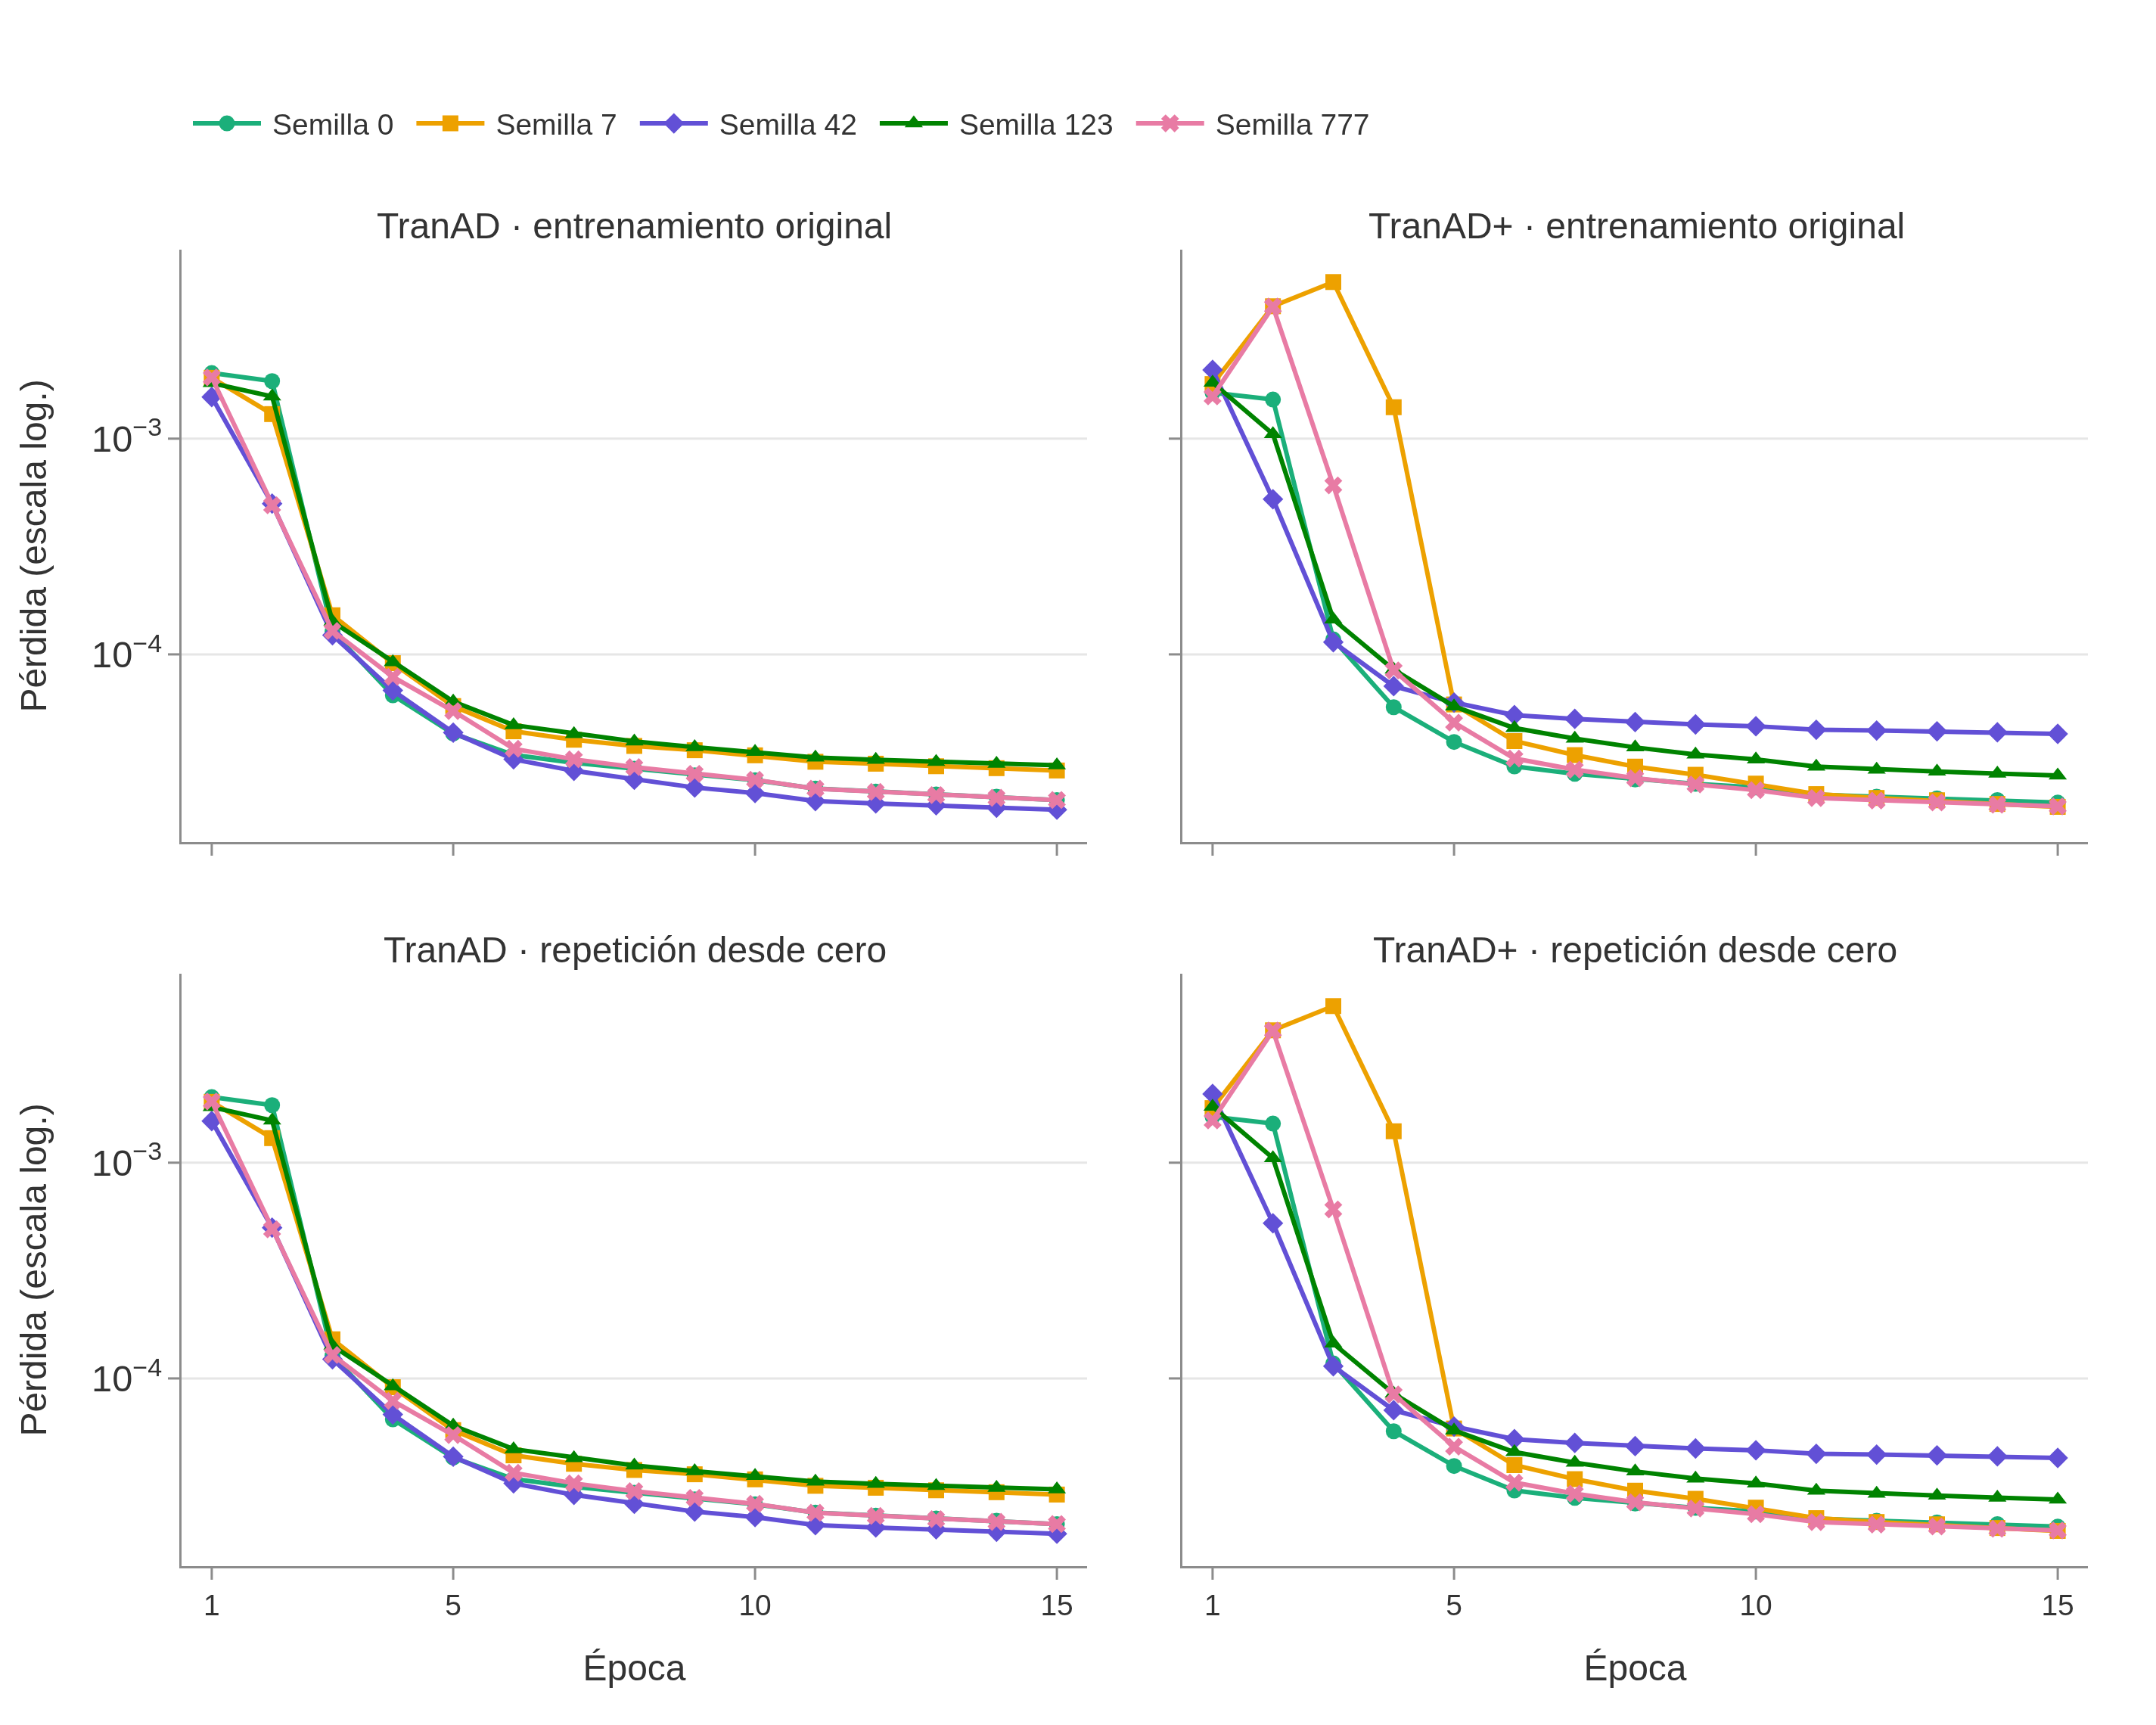

Figura guardada: fig_5_1_1_perdida_original_y_repeticion (.html y .png)


In [6]:
# --- Pérdida por época: original (fila superior) y repetición desde cero (fila inferior) ---
TITULO_TIPO = {"original": "entrenamiento original", "repeticion": "repetición desde cero"}
tipos = list(TITULO_TIPO) if HAY_REPETICION else ["original"]

# Formato largo: una fila por modelo, semilla, época y tipo de entrenamiento
perdidas_largas = pd.concat([
    reproducibilidad[["modelo", "semilla", "epoca", "perdida"]].assign(tipo="original"),
    reproducibilidad[["modelo", "semilla", "epoca", "perdida_repeticion"]]
        .rename(columns={"perdida_repeticion": "perdida"}).assign(tipo="repeticion"),
], ignore_index=True)
perdidas_largas = perdidas_largas[perdidas_largas["tipo"].isin(tipos)]

fig = make_subplots(rows=len(tipos), cols=2, shared_xaxes=True, shared_yaxes=True,
                    horizontal_spacing=0.05, vertical_spacing=0.10,
                    subplot_titles=[f"{MODELOS[m]} · {TITULO_TIPO[t]}" for t in tipos for m in MODELOS])
for fila, tipo in enumerate(tipos, start=1):
    for col, modelo in enumerate(MODELOS, start=1):
        for semilla in SEMILLAS:
            d = perdidas_largas[(perdidas_largas["tipo"] == tipo) & (perdidas_largas["modelo"] == modelo)
                                & (perdidas_largas["semilla"] == semilla)].sort_values("epoca")
            fig.add_trace(go.Scatter(
                x=d["epoca"], y=d["perdida"], mode="lines+markers", name=f"Semilla {semilla}",
                legendgroup=str(semilla), showlegend=(fila == 1 and col == 1),  # una entrada de leyenda por semilla
                line=dict(color=COLOR_SEMILLA[semilla], width=2),
                marker=dict(symbol=SIMBOLO_SEMILLA[semilla], size=7, color=COLOR_SEMILLA[semilla]),
                hovertemplate=(f"{MODELOS[modelo]} s{semilla} · {TITULO_TIPO[tipo]}"
                               "<br>Época %{x}<br>Pérdida: %{y:.6e}<extra></extra>")),
                row=fila, col=col)

# Mismo eje Y logarítmico, con rango fijo, en todos los paneles (sin rango fijo, Kaleido puede exportarlos vacíos)
limites = np.log10([perdidas_largas["perdida"].min(), perdidas_largas["perdida"].max()]) + np.array([-0.15, 0.15])
fig.update_yaxes(type="log", dtick=1, exponentformat="power", range=list(limites))
for fila in range(1, len(tipos) + 1):
    fig.update_yaxes(title_text="Pérdida (escala log.)", row=fila, col=1)
fig.update_xaxes(tickvals=[1, 5, 10, 15], range=[0.5, N_EPOCAS + 0.5])
fig.update_xaxes(title_text="Época", row=len(tipos))
fig.update_layout(legend_y=1.07, margin=dict(t=110, b=70, l=80, r=30))
guardar_figura(fig, "fig_5_1_1_perdida_original_y_repeticion", ancho=950, alto=380 * len(tipos))

### 3.3 Tabla: pérdida en la última época, por arquitectura y semilla

In [7]:
# --- Pérdida de la época 15, en unidades de 10⁻⁵ (Tabla 11 de la memoria) ---
ultima = perdidas[perdidas["epoca"] == N_EPOCAS]
tabla_perdida_final = (ultima.pivot(index="modelo", columns="semilla", values="perdida") * 1e5).round(2)
tabla_perdida_final = tabla_perdida_final.reindex(index=list(MODELOS), columns=SEMILLAS)
display(tabla_perdida_final.rename(index=MODELOS))

PERDIDA_MEMORIA = {"tranad": [2.11, 2.90, 1.91, 3.06, 2.11], "tranadplus": [2.06, 1.96, 4.28, 2.75, 1.97]}
for modelo, valores in PERDIDA_MEMORIA.items():
    for semilla, valor in zip(SEMILLAS, valores):
        comprobar(f"pérdida final ×10⁻⁵, {MODELOS[modelo]} s{semilla}", tabla_perdida_final.loc[modelo, semilla], valor)

tabla = tabla_perdida_final.rename(index=MODELOS).reset_index(names="modelo")
tabla.columns = ["modelo"] + [f"semilla_{s}" for s in SEMILLAS]
guardar_tabla(tabla, "tabla_5_1_1_perdida_final_por_semilla")
REGISTRO["resultados"]["perdida_final_x1e-5"] = tabla.to_dict(orient="records")

semilla,0,7,42,123,777
modelo,,,,,
TranAD,2.11,2.90,1.91,3.06,2.11
TranAD+,2.06,1.96,4.28,2.75,1.97


  coincide: pérdida final ×10⁻⁵, TranAD s0 = 2.11 (memoria: 2.11)
  coincide: pérdida final ×10⁻⁵, TranAD s7 = 2.9 (memoria: 2.9)
  coincide: pérdida final ×10⁻⁵, TranAD s42 = 1.91 (memoria: 1.91)
  coincide: pérdida final ×10⁻⁵, TranAD s123 = 3.06 (memoria: 3.06)
  coincide: pérdida final ×10⁻⁵, TranAD s777 = 2.11 (memoria: 2.11)
  coincide: pérdida final ×10⁻⁵, TranAD+ s0 = 2.06 (memoria: 2.06)
  coincide: pérdida final ×10⁻⁵, TranAD+ s7 = 1.96 (memoria: 1.96)
  coincide: pérdida final ×10⁻⁵, TranAD+ s42 = 4.28 (memoria: 4.28)
  coincide: pérdida final ×10⁻⁵, TranAD+ s123 = 2.75 (memoria: 2.75)
  coincide: pérdida final ×10⁻⁵, TranAD+ s777 = 1.97 (memoria: 1.97)
Tabla guardada: tabla_5_1_1_perdida_final_por_semilla.csv


## 4. Apartado 5.1.2 — Concordancia de alertas entre arquitecturas

### 4.1 Figura: índice de Jaccard entre las 100 alertas principales de cada pareja de modelos

Si las dos arquitecturas detectaran cosas distintas, el bloque TranAD–TranAD+ sería más claro que los dos bloques de una misma arquitectura.

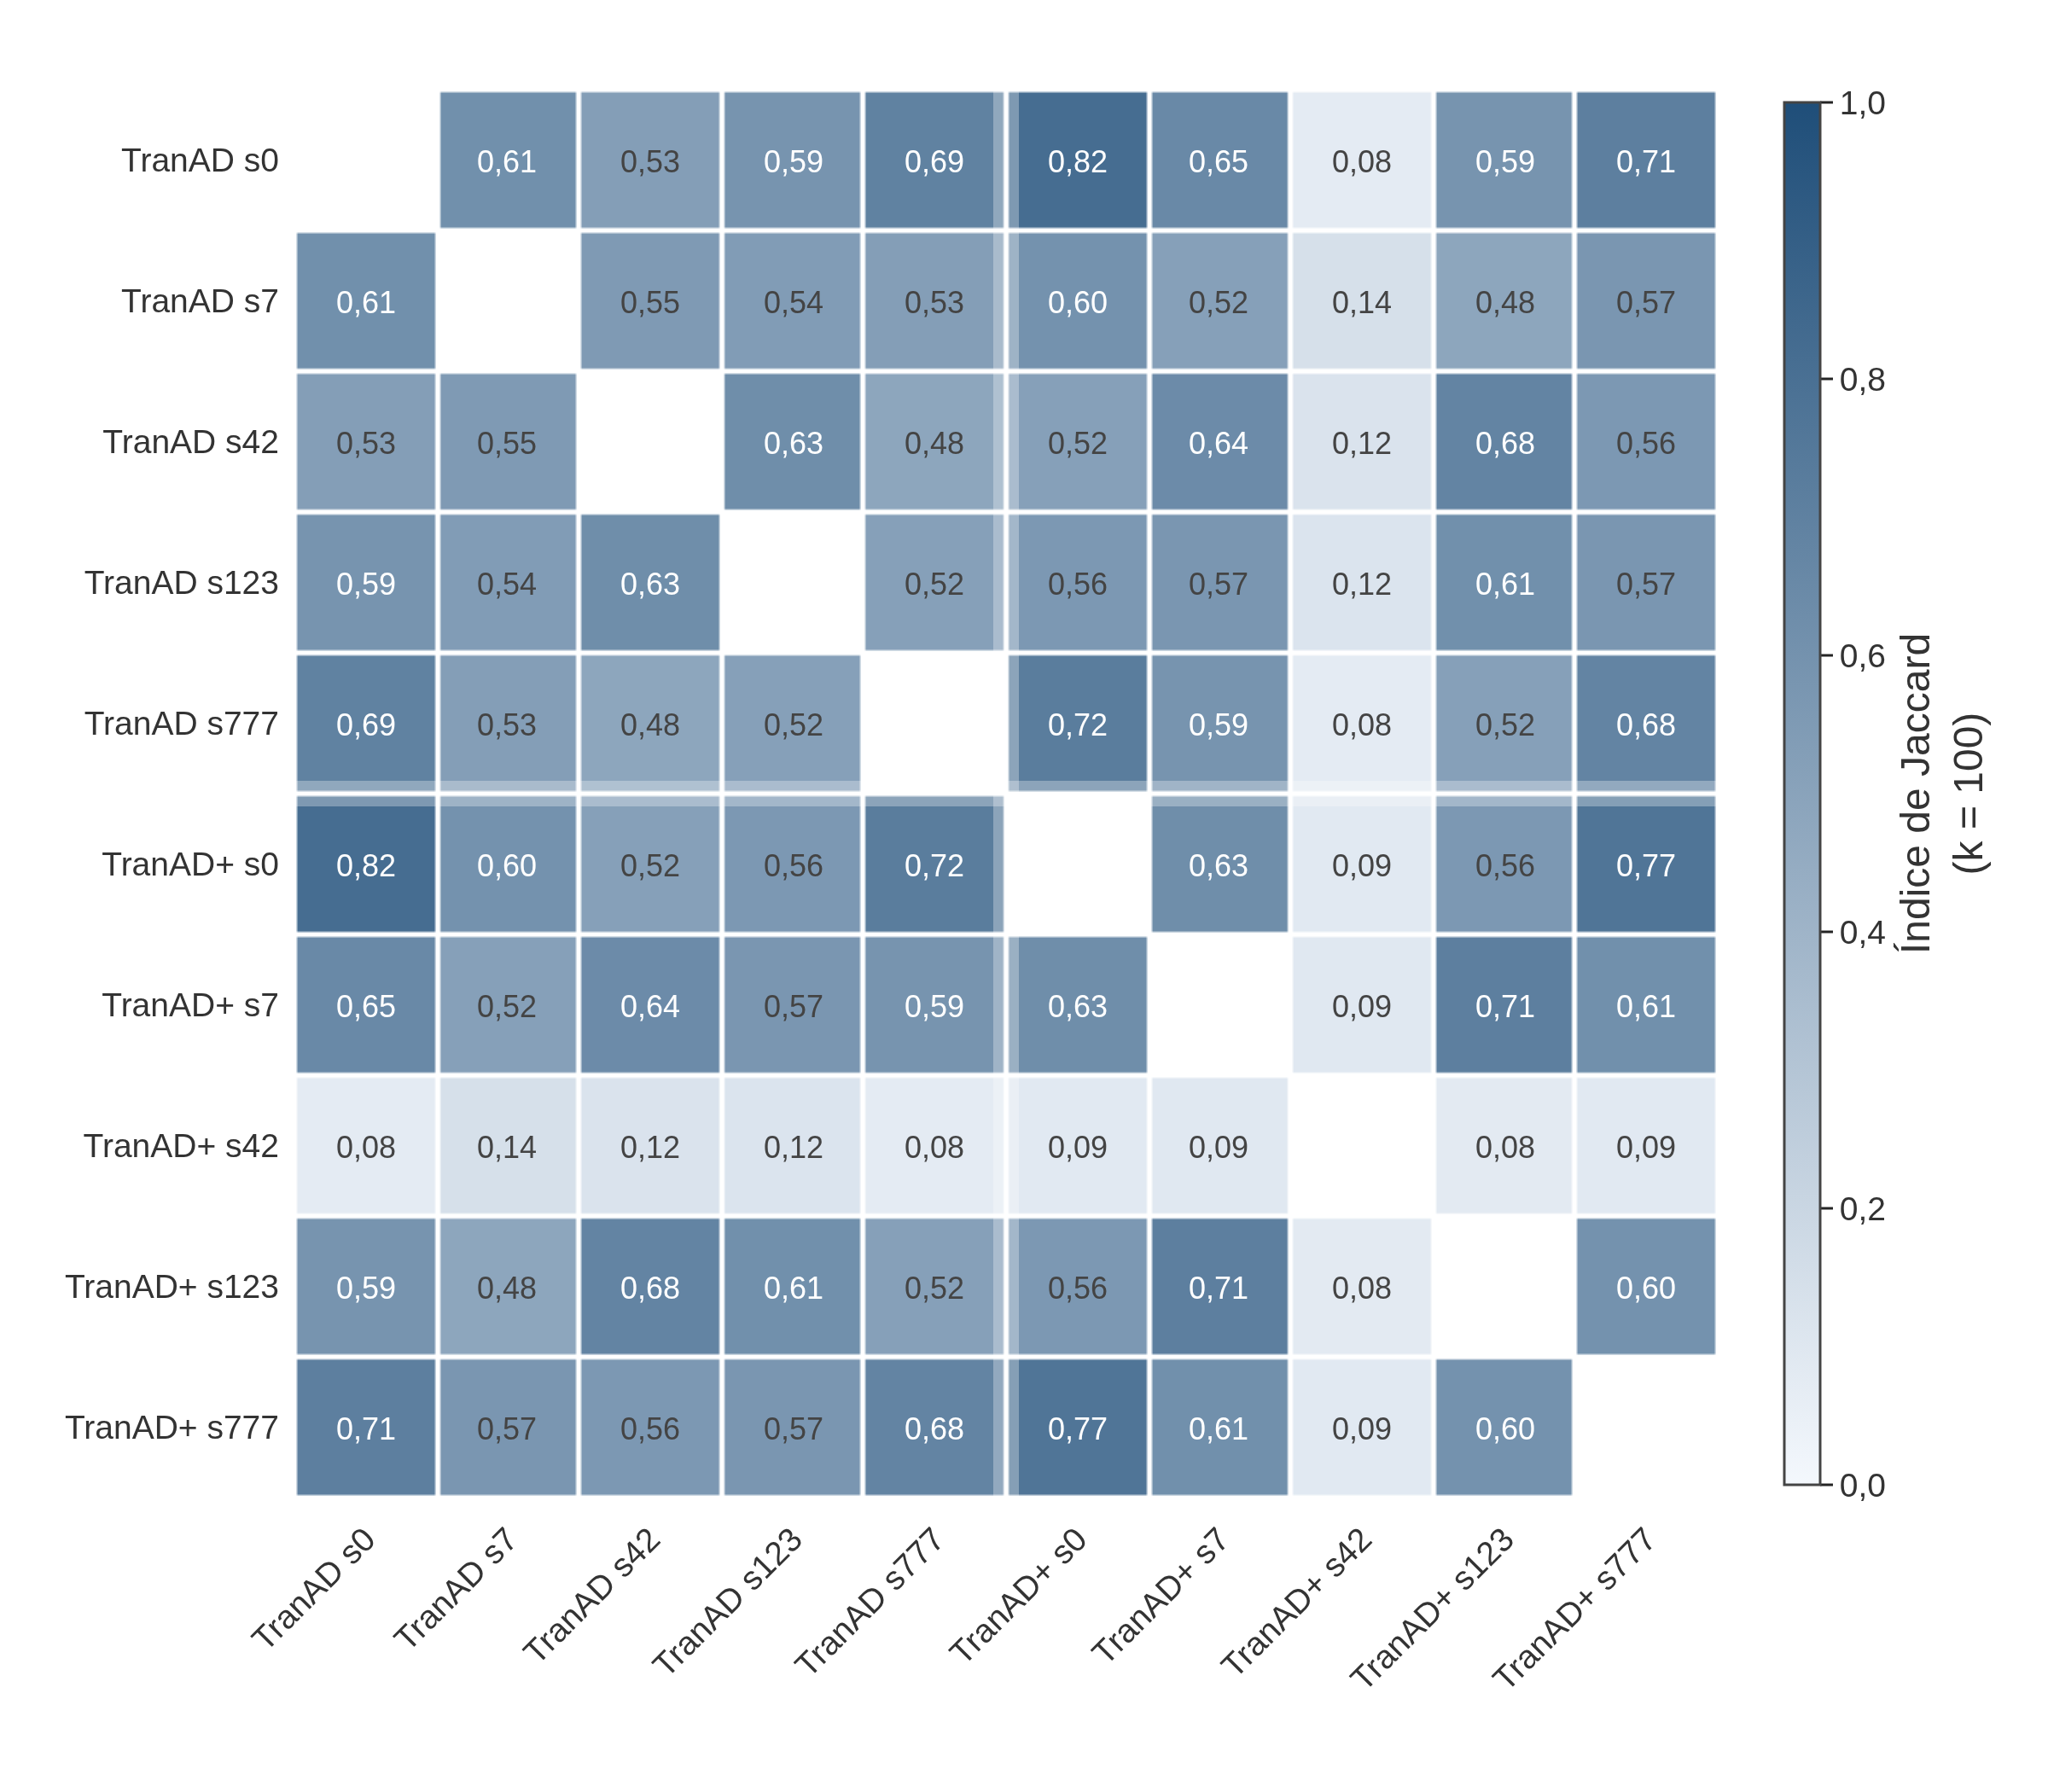

Figura guardada: fig_5_1_2a_mapa_calor_jaccard (.html y .png)
Rango sin la semilla 42: todas las parejas 0.48–0.82 | solo entre arquitecturas 0.48–0.82
  coincide: Jaccard mínimo sin la semilla 42 (k = 100) = 0.48 (memoria: 0.48)
  coincide: Jaccard máximo sin la semilla 42 (k = 100) = 0.82 (memoria: 0.82)


In [8]:
# --- Mapa de calor del índice de Jaccard entre los 10 modelos (k = 100) ---
pares = jaccard[jaccard["k"] == K_PRINCIPAL]
matriz = pd.DataFrame(np.nan, index=CORRIDAS, columns=CORRIDAS)
for _, r in pares.iterrows():  # matriz simétrica; la diagonal queda vacía
    matriz.loc[r["corrida_1"], r["corrida_2"]] = r["jaccard"]
    matriz.loc[r["corrida_2"], r["corrida_1"]] = r["jaccard"]
nombres = [etiqueta(c) for c in CORRIDAS]
textos = [["" if np.isnan(v) else f"{v:.2f}".replace(".", ",") for v in fila] for fila in matriz.values]

fig = go.Figure(go.Heatmap(
    z=matriz.values, x=nombres, y=nombres, zmin=0, zmax=1, xgap=2, ygap=2,
    colorscale=[[0, "#f4f8fd"], [1, "#1f4e79"]],  # un solo tono, de claro a oscuro
    text=textos, texttemplate="%{text}", textfont=dict(size=12),
    hovertemplate="%{y} · %{x}<br>Índice de Jaccard: %{z:.3f}<extra></extra>",
    colorbar=dict(title=dict(text=f"Índice de Jaccard<br>(k = {K_PRINCIPAL})", side="right"), thickness=14,
                  tickformat=".1f")))
# Líneas blancas que separan los bloques de cada arquitectura
fig.add_shape(type="line", x0=4.5, x1=4.5, y0=-0.5, y1=9.5, line=dict(color="white", width=10), layer="above")
fig.add_shape(type="line", x0=-0.5, x1=9.5, y0=4.5, y1=4.5, line=dict(color="white", width=10), layer="above")
fig.update_xaxes(showline=False, ticks="", tickangle=-45)
fig.update_yaxes(showline=False, ticks="", autorange="reversed", showgrid=False)
fig.update_layout(margin=dict(l=110, r=30, t=30, b=110))
guardar_figura(fig, "fig_5_1_2a_mapa_calor_jaccard", ancho=800, alto=700)

# El texto de la memoria da el rango de las casillas sin la semilla 42 de TranAD+
sin_atipica = pares[(pares["corrida_1"] != SEMILLA_ATIPICA) & (pares["corrida_2"] != SEMILLA_ATIPICA)]
entre_sin = sin_atipica[sin_atipica["grupo"] == "entre_modelos"]["jaccard"]
print(f"Rango sin la semilla 42: todas las parejas {sin_atipica['jaccard'].min():.2f}–{sin_atipica['jaccard'].max():.2f} | "
      f"solo entre arquitecturas {entre_sin.min():.2f}–{entre_sin.max():.2f}")
comprobar("Jaccard mínimo sin la semilla 42 (k = 100)", round(float(sin_atipica["jaccard"].min()), 2), 0.48)
comprobar("Jaccard máximo sin la semilla 42 (k = 100)", round(float(sin_atipica["jaccard"].max()), 2), 0.82)

### 4.2 Figura: ¿cambia la conclusión si se comparan más o menos alertas?

Una línea por grupo de parejas, con la mediana del índice de Jaccard para k = 50, 100, 200 y 500. Si TranAD+ detectara alertas distintas, la línea «entre arquitecturas» quedaría por debajo de las otras dos.

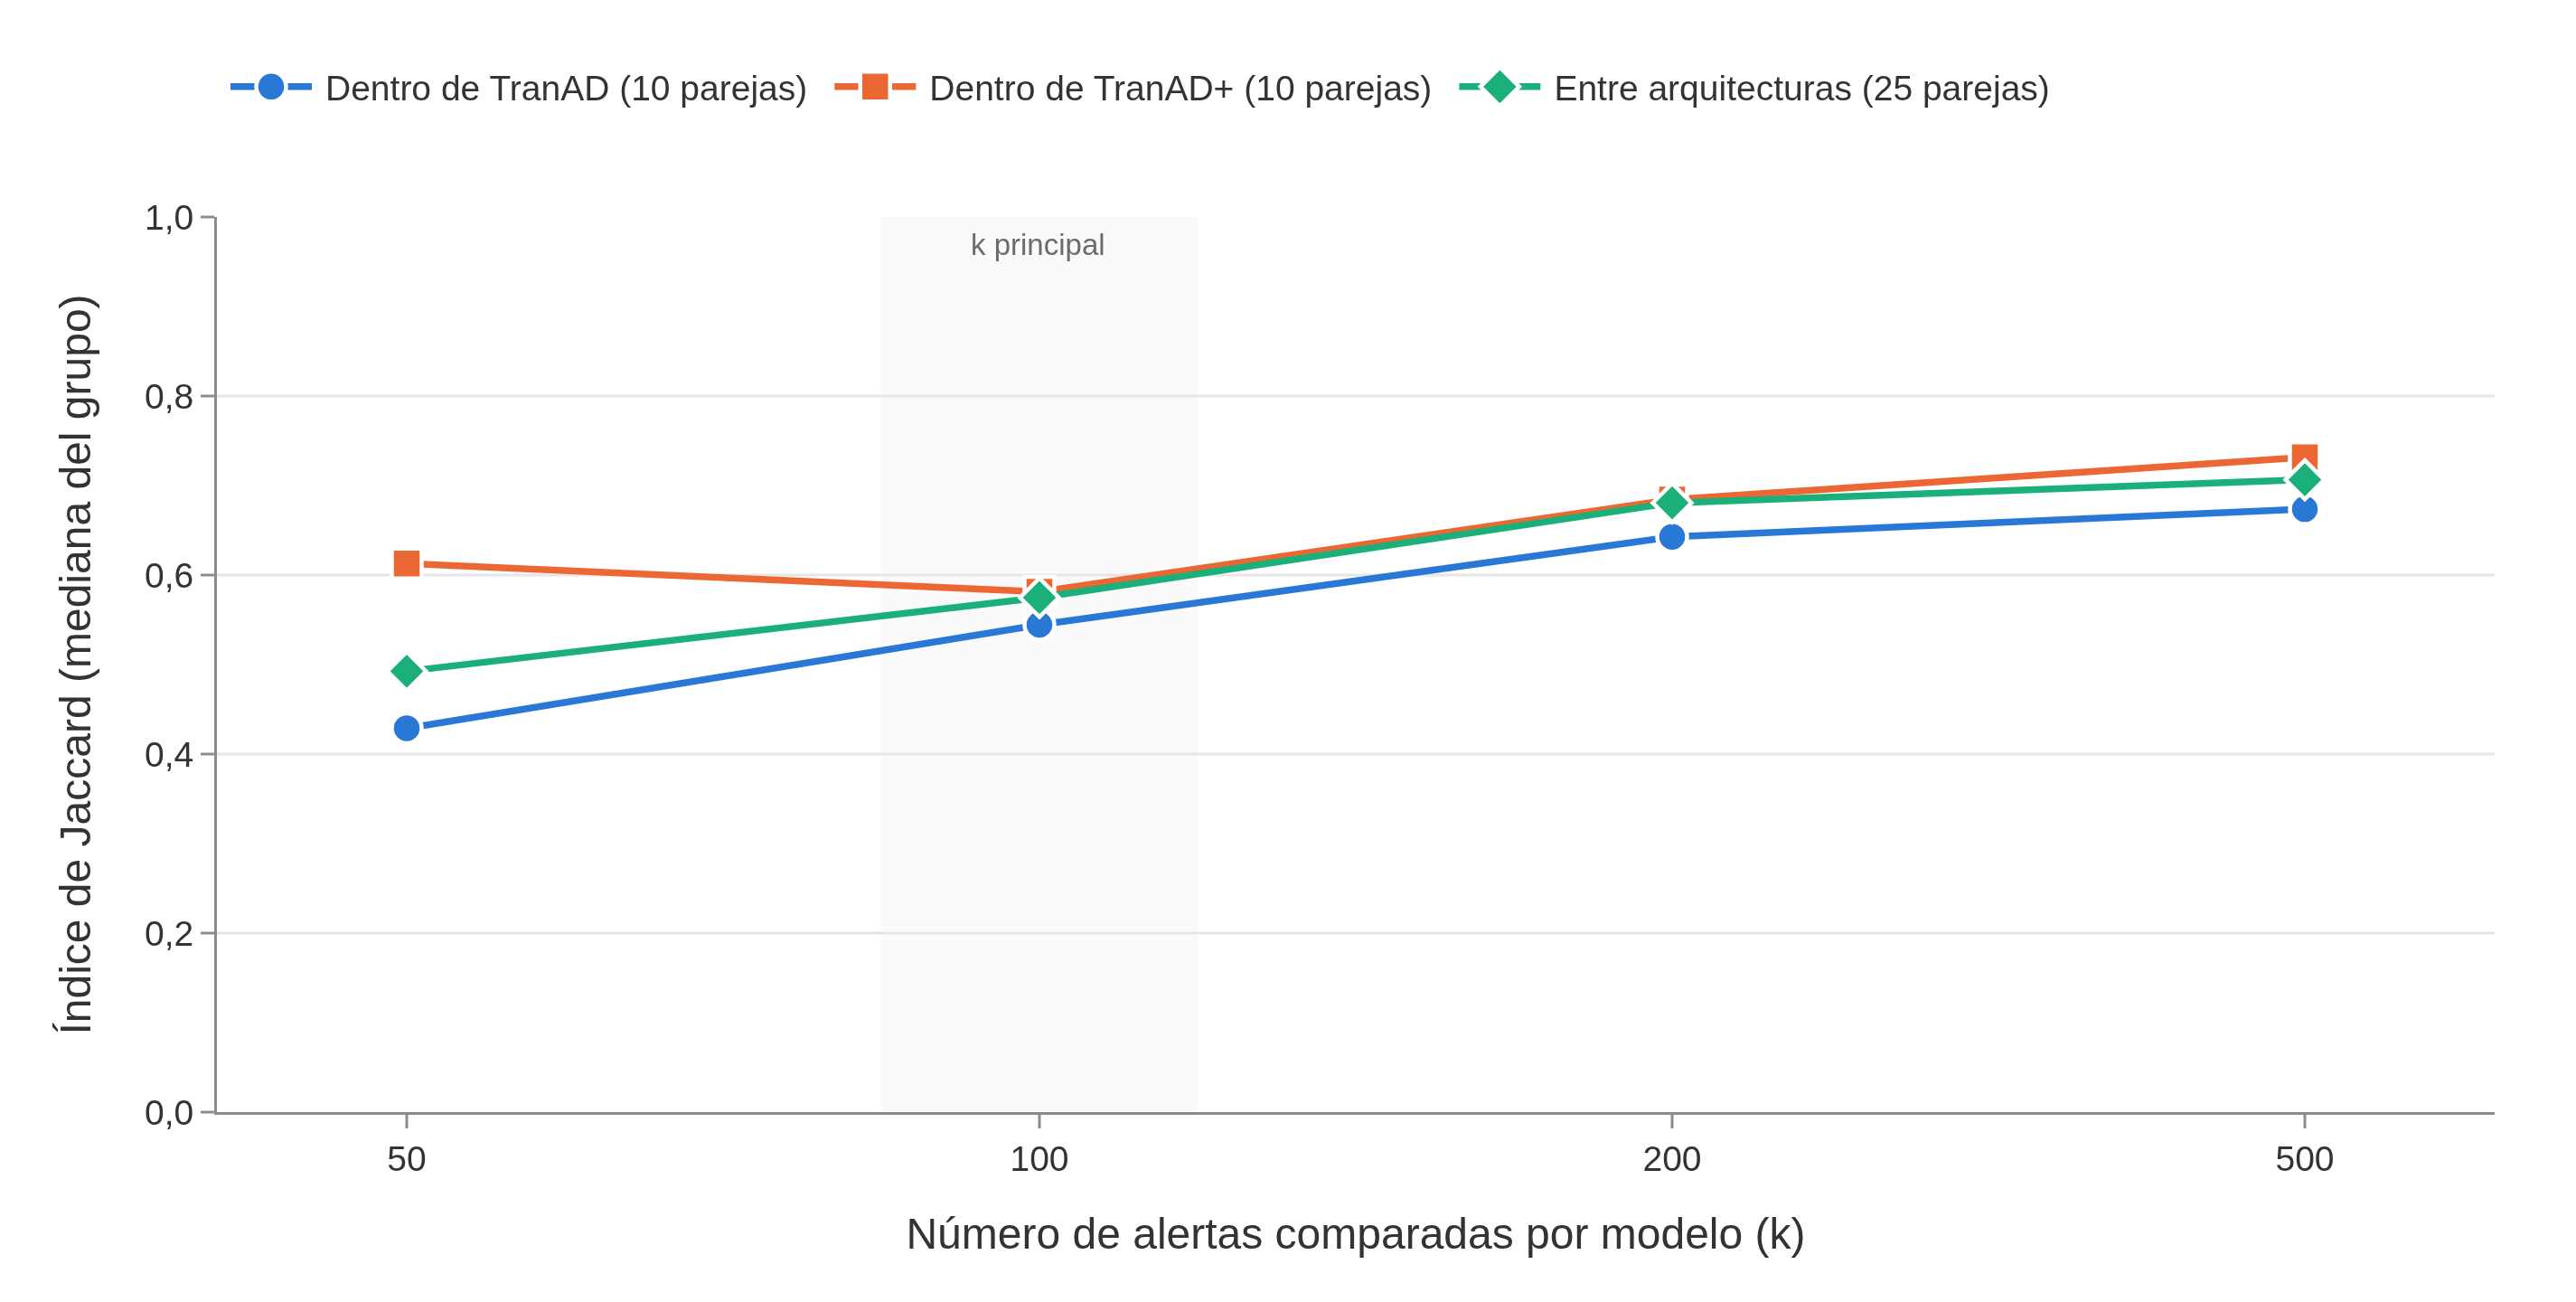

Figura guardada: fig_5_1_2b_jaccard_segun_k (.html y .png)


,k,grupo,parejas,mediana,minimo,maximo,mediana_sin_s42
0,50,Dentro de TranAD,10,0.429,0.282,0.515,0.429
1,50,Dentro de TranAD+,10,0.613,0.064,0.695,0.667
2,50,Entre arquitecturas,25,0.493,0.053,0.695,0.504
3,100,Dentro de TranAD,10,0.544,0.481,0.695,0.544
4,100,Dentro de TranAD+,10,0.581,0.081,0.770,0.619
5,100,Entre arquitecturas,25,0.575,0.075,0.818,0.587
6,200,Dentro de TranAD,10,0.643,0.569,0.786,0.643
7,200,Dentro de TranAD+,10,0.684,0.102,0.835,0.717
8,200,Entre arquitecturas,25,0.681,0.096,0.786,0.691
9,500,Dentro de TranAD,10,0.674,0.616,0.770,0.674


Tabla guardada: tabla_5_1_2_jaccard_por_k.csv


In [9]:
# --- Mediana del índice de Jaccard de cada grupo de parejas, según k ---
GRUPOS_J = {"dentro_tranad": ("Dentro de TranAD", COLOR_MODELO["tranad"], "circle"),
            "dentro_tranadplus": ("Dentro de TranAD+", COLOR_MODELO["tranadplus"], "square"),
            "entre_modelos": ("Entre arquitecturas", COLOR_COMUN, "diamond")}
jaccard["con_atipica"] = (jaccard["corrida_1"] == SEMILLA_ATIPICA) | (jaccard["corrida_2"] == SEMILLA_ATIPICA)
valores_k = sorted(jaccard["k"].unique())
posiciones = list(range(len(valores_k)))  # k equiespaciados en el eje

fig = go.Figure()
i_principal = valores_k.index(K_PRINCIPAL)  # banda gris que señala el valor principal de k
fig.add_vrect(x0=i_principal - 0.25, x1=i_principal + 0.25, fillcolor="#efefef", line_width=0, layer="below")
fig.add_annotation(x=i_principal, y=0.97, text="k principal", showarrow=False, font=dict(size=11, color=TINTA_SUAVE))
for grupo, (nombre, color, simbolo) in GRUPOS_J.items():
    d = jaccard[jaccard["grupo"] == grupo]
    medianas = d.groupby("k")["jaccard"].median().reindex(valores_k)
    n_parejas = int(d.groupby("k").size().iloc[0])
    fig.add_trace(go.Scatter(
        x=posiciones, y=medianas.values, mode="lines+markers", name=f"{nombre} ({n_parejas} parejas)",
        line=dict(color=color, width=2.5),
        marker=dict(symbol=simbolo, size=11, color=color, line=dict(color="white", width=1.5)),
        customdata=valores_k, hovertemplate=nombre + "<br>k = %{customdata}<br>Mediana: %{y:.3f}<extra></extra>"))
fig.update_xaxes(tickvals=posiciones, ticktext=[str(k) for k in valores_k],
                 title_text="Número de alertas comparadas por modelo (k)", range=[-0.3, len(valores_k) - 0.7])
fig.update_yaxes(range=[0, 1], tickformat=".1f", title_text="Índice de Jaccard (mediana del grupo)")
fig.update_layout(legend_y=1.1, margin=dict(t=80, b=70, l=80, r=30))
guardar_figura(fig, "fig_5_1_2b_jaccard_segun_k")

# Tabla completa para el anexo: mediana, mínimo y máximo por grupo y k, y mediana sin la semilla 42
filas = []
for (k, grupo), d in jaccard.groupby(["k", "grupo"]):
    filas.append({"k": k, "grupo": GRUPOS_J[grupo][0], "parejas": len(d),
                  "mediana": round(d["jaccard"].median(), 3), "minimo": round(d["jaccard"].min(), 3),
                  "maximo": round(d["jaccard"].max(), 3),
                  "mediana_sin_s42": round(d[~d["con_atipica"]]["jaccard"].median(), 3)})
tabla_jaccard = pd.DataFrame(filas)
display(tabla_jaccard)
guardar_tabla(tabla_jaccard, "tabla_5_1_2_jaccard_por_k")
REGISTRO["resultados"]["jaccard"] = tabla_jaccard.to_dict(orient="records")

## 5. Apartado 5.1.3 — Alertas de consenso

### 5.1 Figura: señal protagonista de las alertas comunes a TranAD y TranAD+

Cada alerta común se clasifica por la familia de su señal protagonista (notebook 03, sección 6). Solo se representan las comunes: las exclusivas de una arquitectura no se interpretan, porque H1 no se cumple (apartado 2.2.2).

familia,FAM_1,FAM_2,FAM_3,FAM_4,Sin protagonista
grupo,,,,,
Comunes,8,36,2,24,4
Solo TranAD,3,6,13,0,0
Solo TranAD+,1,6,0,7,0


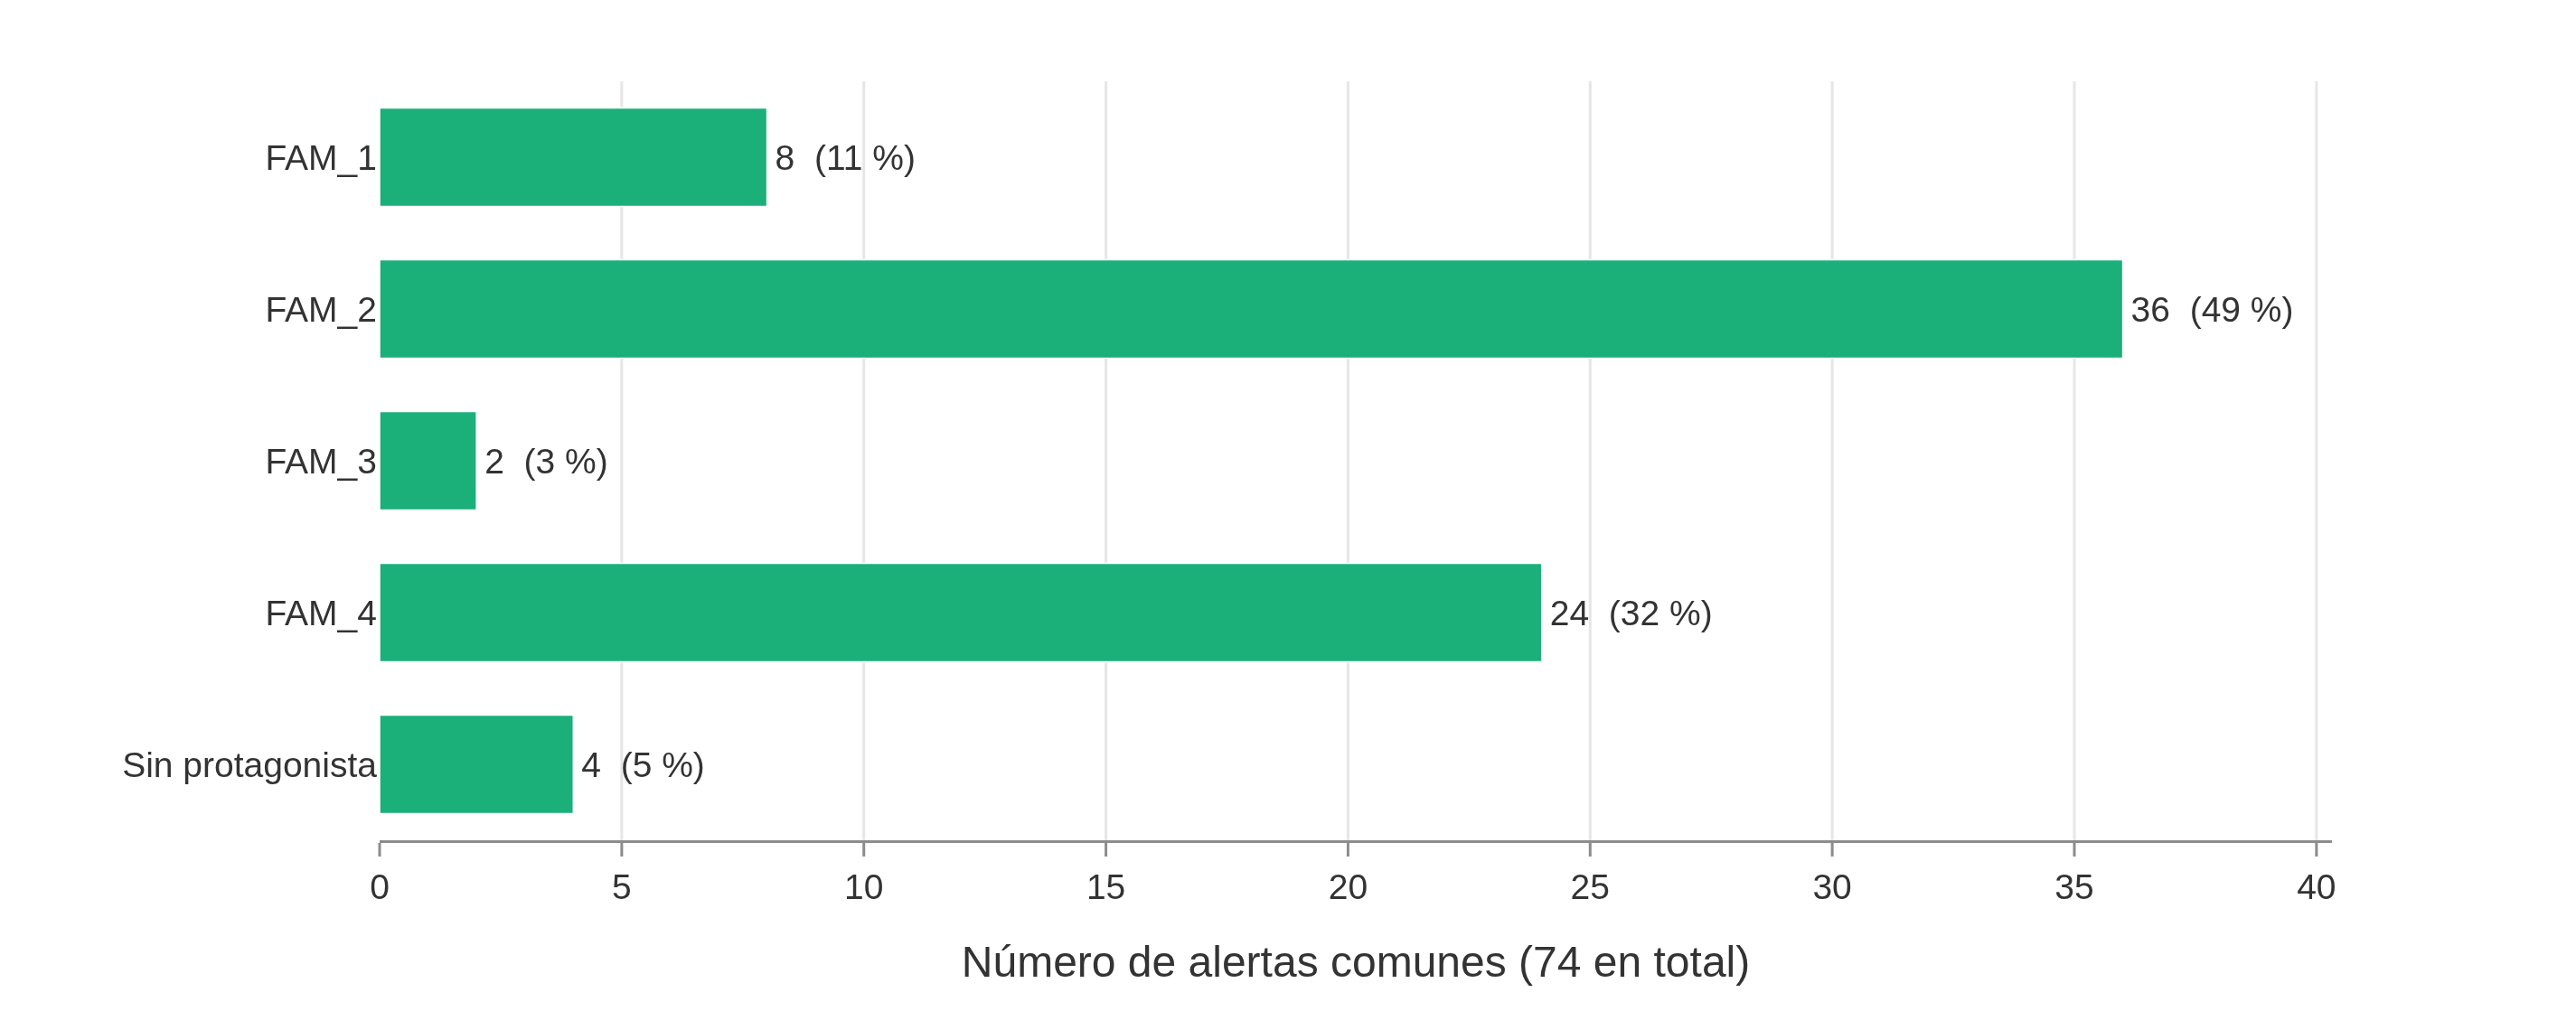

Figura guardada: fig_5_1_3_familias_alertas_comunes (.html y .png)
  coincide: porcentaje de alertas comunes de FAM_2 = 49 (memoria: 49)
  coincide: porcentaje de alertas comunes de FAM_4 = 32 (memoria: 32)
Tabla guardada: tabla_5_1_3_familias_por_grupo.csv


In [10]:
# --- Familia de la señal protagonista de las alertas comunes ---
GRUPOS_C = {"comun": "Comunes", "solo_tranad": "Solo TranAD", "solo_tranadplus": "Solo TranAD+"}
ORDEN_FAM = ORDEN_FAMILIAS + ["Sin protagonista"]
conteo = (pd.crosstab(familias["grupo"], familias["familia"])
          .reindex(index=list(GRUPOS_C), columns=ORDEN_FAM, fill_value=0))
display(conteo.rename(index=GRUPOS_C))

comunes = conteo.loc["comun"]
total = int(comunes.sum())
fig = go.Figure(go.Bar(
    y=ORDEN_FAM, x=comunes.values, orientation="h",
    marker=dict(color=COLOR_COMUN),  # un solo color: una sola serie
    text=[f"{v}  ({v / total * 100:.0f} %)" for v in comunes.values],  # número y porcentaje junto a cada barra
    textposition="outside", cliponaxis=False,
    hovertemplate="%{y}: %{x} alertas<extra></extra>"))
fig.update_layout(bargap=0.35, showlegend=False, margin=dict(t=30, b=70, l=140, r=90))
fig.update_yaxes(autorange="reversed", showgrid=False, showline=False, ticks="")  # mismo orden que ORDEN_FAM
fig.update_xaxes(range=[0, comunes.max() * 1.12], showgrid=True, gridcolor=REJILLA,
                 title_text=f"Número de alertas comunes ({total} en total)")
guardar_figura(fig, "fig_5_1_3_familias_alertas_comunes", alto=380)

# Porcentajes que cita la memoria (Tabla 12)
comprobar("porcentaje de alertas comunes de FAM_2", round(100 * comunes["FAM_2"] / total), 49)
comprobar("porcentaje de alertas comunes de FAM_4", round(100 * comunes["FAM_4"] / total), 32)

guardar_tabla(conteo.rename(index=GRUPOS_C).reset_index(names="grupo"), "tabla_5_1_3_familias_por_grupo")
REGISTRO["resultados"]["familias"] = conteo.rename(index=GRUPOS_C).to_dict(orient="index")

## 6. Apartado 5.1.4 — Tasa de alarma y detección de valores imposibles

Una marca por semilla, con la media de cada arquitectura y, en la detección, el resultado de la ejecución exploratoria única (sin semilla fija, apartado 4.3.1). Son dos medidas distintas, así que van en dos paneles.

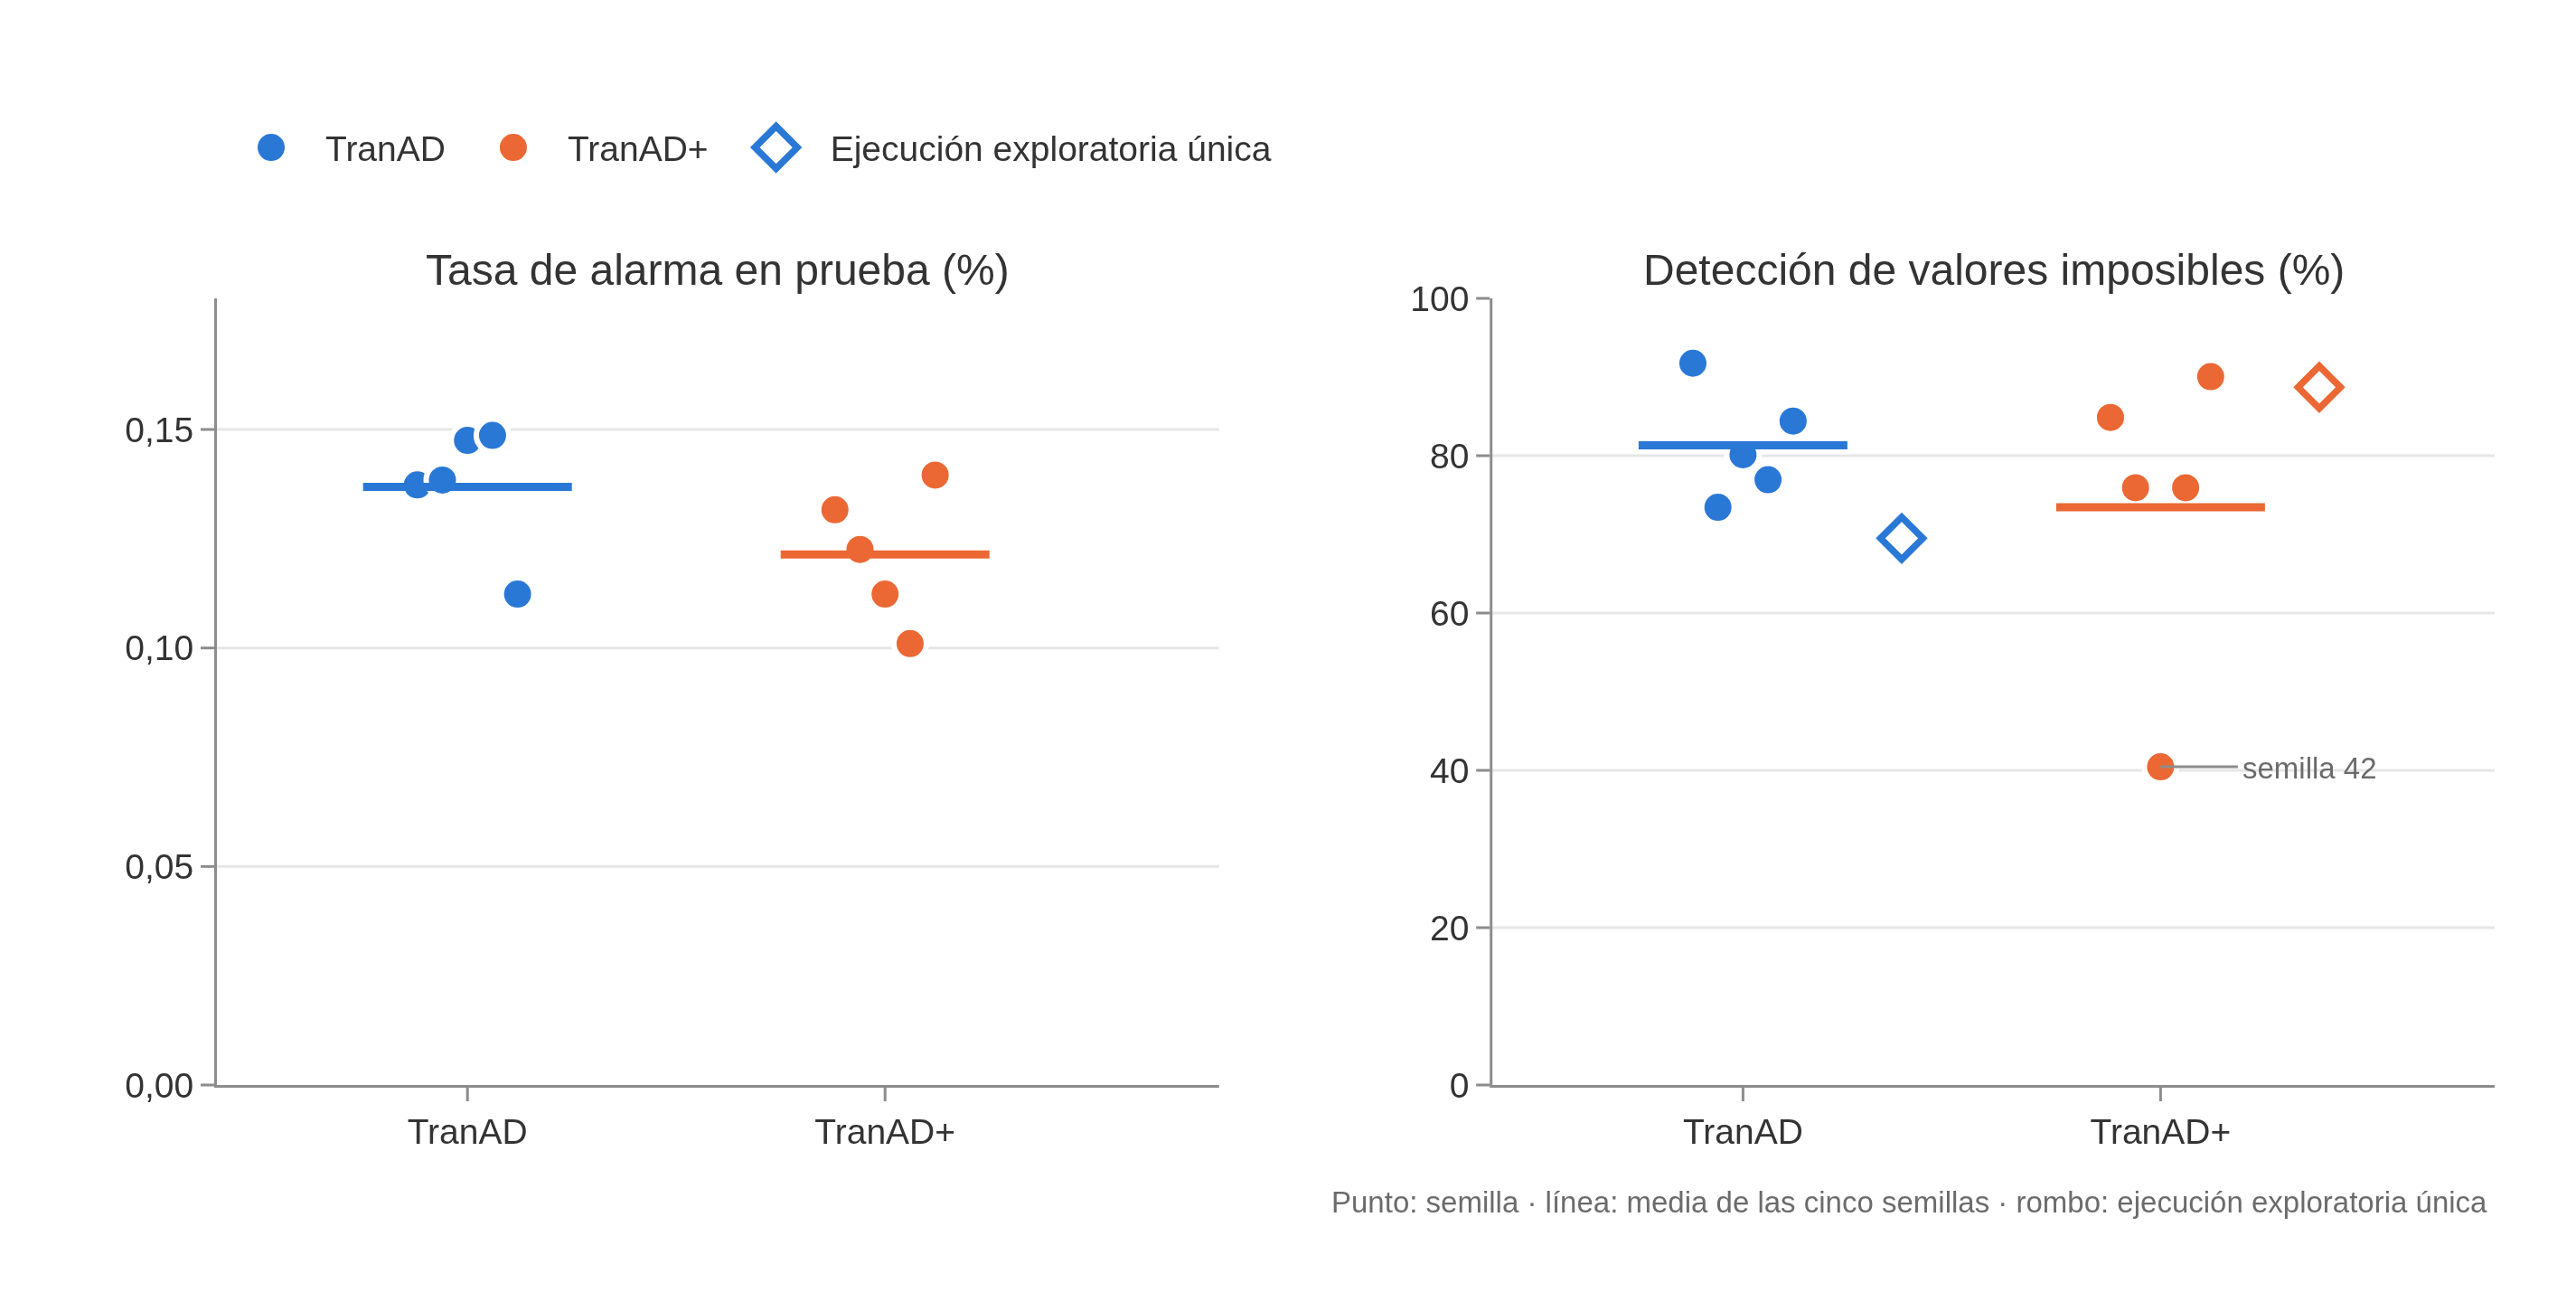

Figura guardada: fig_5_1_4_pot_por_semilla (.html y .png)


,modelo,umbral_pot,alertas_prueba,tasa_alarma_prueba_pct,deteccion_valores_imposibles_pct
0,TranAD s0,0.000676,121,0.137,91.8
1,TranAD s7,0.000954,122,0.138,73.4
2,TranAD s42,0.000770,130,0.148,80.1
3,TranAD s123,0.000919,131,0.149,76.9
4,TranAD s777,0.000682,99,0.112,84.4
5,TranAD+ s0,0.000786,116,0.132,84.9
6,TranAD+ s7,0.000713,108,0.123,75.9
7,TranAD+ s42,0.003204,99,0.112,40.5
8,TranAD+ s123,0.000943,89,0.101,75.9
9,TranAD+ s777,0.000726,123,0.140,90.1


Tabla guardada: tabla_5_1_4_pot_por_semilla.csv
  coincide: veces que el umbral de TranAD+ s42 supera la mediana del resto (redondeado) = 4 (memoria: 4)


In [11]:
# --- Resultados con el umbral POT de cada modelo ---
# Ejecución exploratoria única, sin control de semilla: valores de la memoria (apartado 5.1.4)
EXPLORATORIA_DETECCION = {"tranad": 69.5, "tranadplus": 88.7}

paneles = [("alarma_test_pct", "Tasa de alarma en prueba (%)", 0.18, ".2f"),
           ("deteccion_valores_imposibles_pct", "Detección de valores imposibles (%)", 100, ".1f")]
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.12, subplot_titles=[p[1] for p in paneles])
for col, (columna, titulo, maximo, formato) in enumerate(paneles, start=1):
    for a, (modelo, nombre) in enumerate(MODELOS.items()):
        d = pot[pot["modelo"] == modelo].sort_values("semilla")
        x = a + np.linspace(-0.12, 0.12, len(d))  # separa los puntos con valores parecidos
        fig.add_trace(go.Scatter(
            x=x, y=d[columna], mode="markers", name=nombre, legendgroup=modelo, showlegend=(col == 1),
            marker=dict(size=12, color=COLOR_MODELO[modelo], line=dict(color="white", width=2)),
            customdata=d["semilla"], hovertemplate=f"{nombre} s%{{customdata}}<br>%{{y:{formato}}} %<extra></extra>"),
            row=1, col=col)
        fig.add_trace(go.Scatter(  # media de las cinco semillas
            x=[a - 0.25, a + 0.25], y=[d[columna].mean()] * 2, mode="lines", legendgroup=modelo, showlegend=False,
            line=dict(color=COLOR_MODELO[modelo], width=3),
            hovertemplate=f"{nombre}, media: %{{y:{formato}}} %<extra></extra>"), row=1, col=col)
        if columna == "deteccion_valores_imposibles_pct":
            fig.add_trace(go.Scatter(  # ejecución exploratoria única
                x=[a + 0.38], y=[EXPLORATORIA_DETECCION[modelo]], mode="markers", legendgroup="exploratoria",
                name="Ejecución exploratoria única", showlegend=(modelo == "tranad"),
                marker=dict(symbol="diamond-open", size=12, color=COLOR_MODELO[modelo], line=dict(width=2.5)),
                hovertemplate=f"{nombre}, ejecución exploratoria: %{{y:.1f}} %<extra></extra>"), row=1, col=col)
            if modelo == "tranadplus":  # etiqueta directa de la semilla atípica
                y42 = float(d.loc[d["semilla"] == 42, columna].iloc[0])
                fig.add_annotation(x=a, y=y42, text="semilla 42", showarrow=True, arrowhead=0, ax=55, ay=0,
                                   arrowcolor=GUIA, font=dict(size=11, color=TINTA_SUAVE), row=1, col=col)
    fig.update_yaxes(range=[0, maximo], tickformat=(formato if col == 1 else ""), row=1, col=col)
    fig.update_xaxes(tickvals=[0, 1], ticktext=list(MODELOS.values()), range=[-0.6, 1.8], row=1, col=col)
fig.update_layout(legend_y=1.14, margin_t=110)
nota(fig, "Punto: semilla · línea: media de las cinco semillas · rombo: ejecución exploratoria única", y=-0.12)
guardar_figura(fig, "fig_5_1_4_pot_por_semilla")

# Tabla por semilla, para el anexo
tabla_pot = pd.DataFrame({
    "modelo": pot["corrida"].map(etiqueta), "umbral_pot": pot["umbral_pot"], "alertas_prueba": pot["n_alertas_test"],
    "tasa_alarma_prueba_pct": pot["alarma_test_pct"].round(3),
    "deteccion_valores_imposibles_pct": pot["deteccion_valores_imposibles_pct"].round(1)})
display(tabla_pot)
guardar_tabla(tabla_pot, "tabla_5_1_4_pot_por_semilla")
REGISTRO["resultados"]["pot"] = tabla_pot.to_dict(orient="records")

# El umbral de la semilla 42 de TranAD+ es «unos cuatro veces» el del resto
umbrales = pot.set_index("corrida")["umbral_pot"]
veces = umbrales[SEMILLA_ATIPICA] / umbrales.drop(SEMILLA_ATIPICA).median()
comprobar("veces que el umbral de TranAD+ s42 supera la mediana del resto (redondeado)", round(float(veces)), 4)

## 7. Apartado 5.1.5 — Respuesta a la hipótesis H1

Puntuación mediana de las cinco semillas de cada arquitectura, para cada ventana de prueba. Si las dos arquitecturas detectan lo mismo, los puntos se alinean en la diagonal. Las alertas de consenso van en color; al pasar el ratón por ellas se ve el índice de la ventana.

Correlación de Spearman entre las puntuaciones medianas: 0.935
  coincide: correlación de Spearman entre arquitecturas = 0.94 (memoria: 0.94)


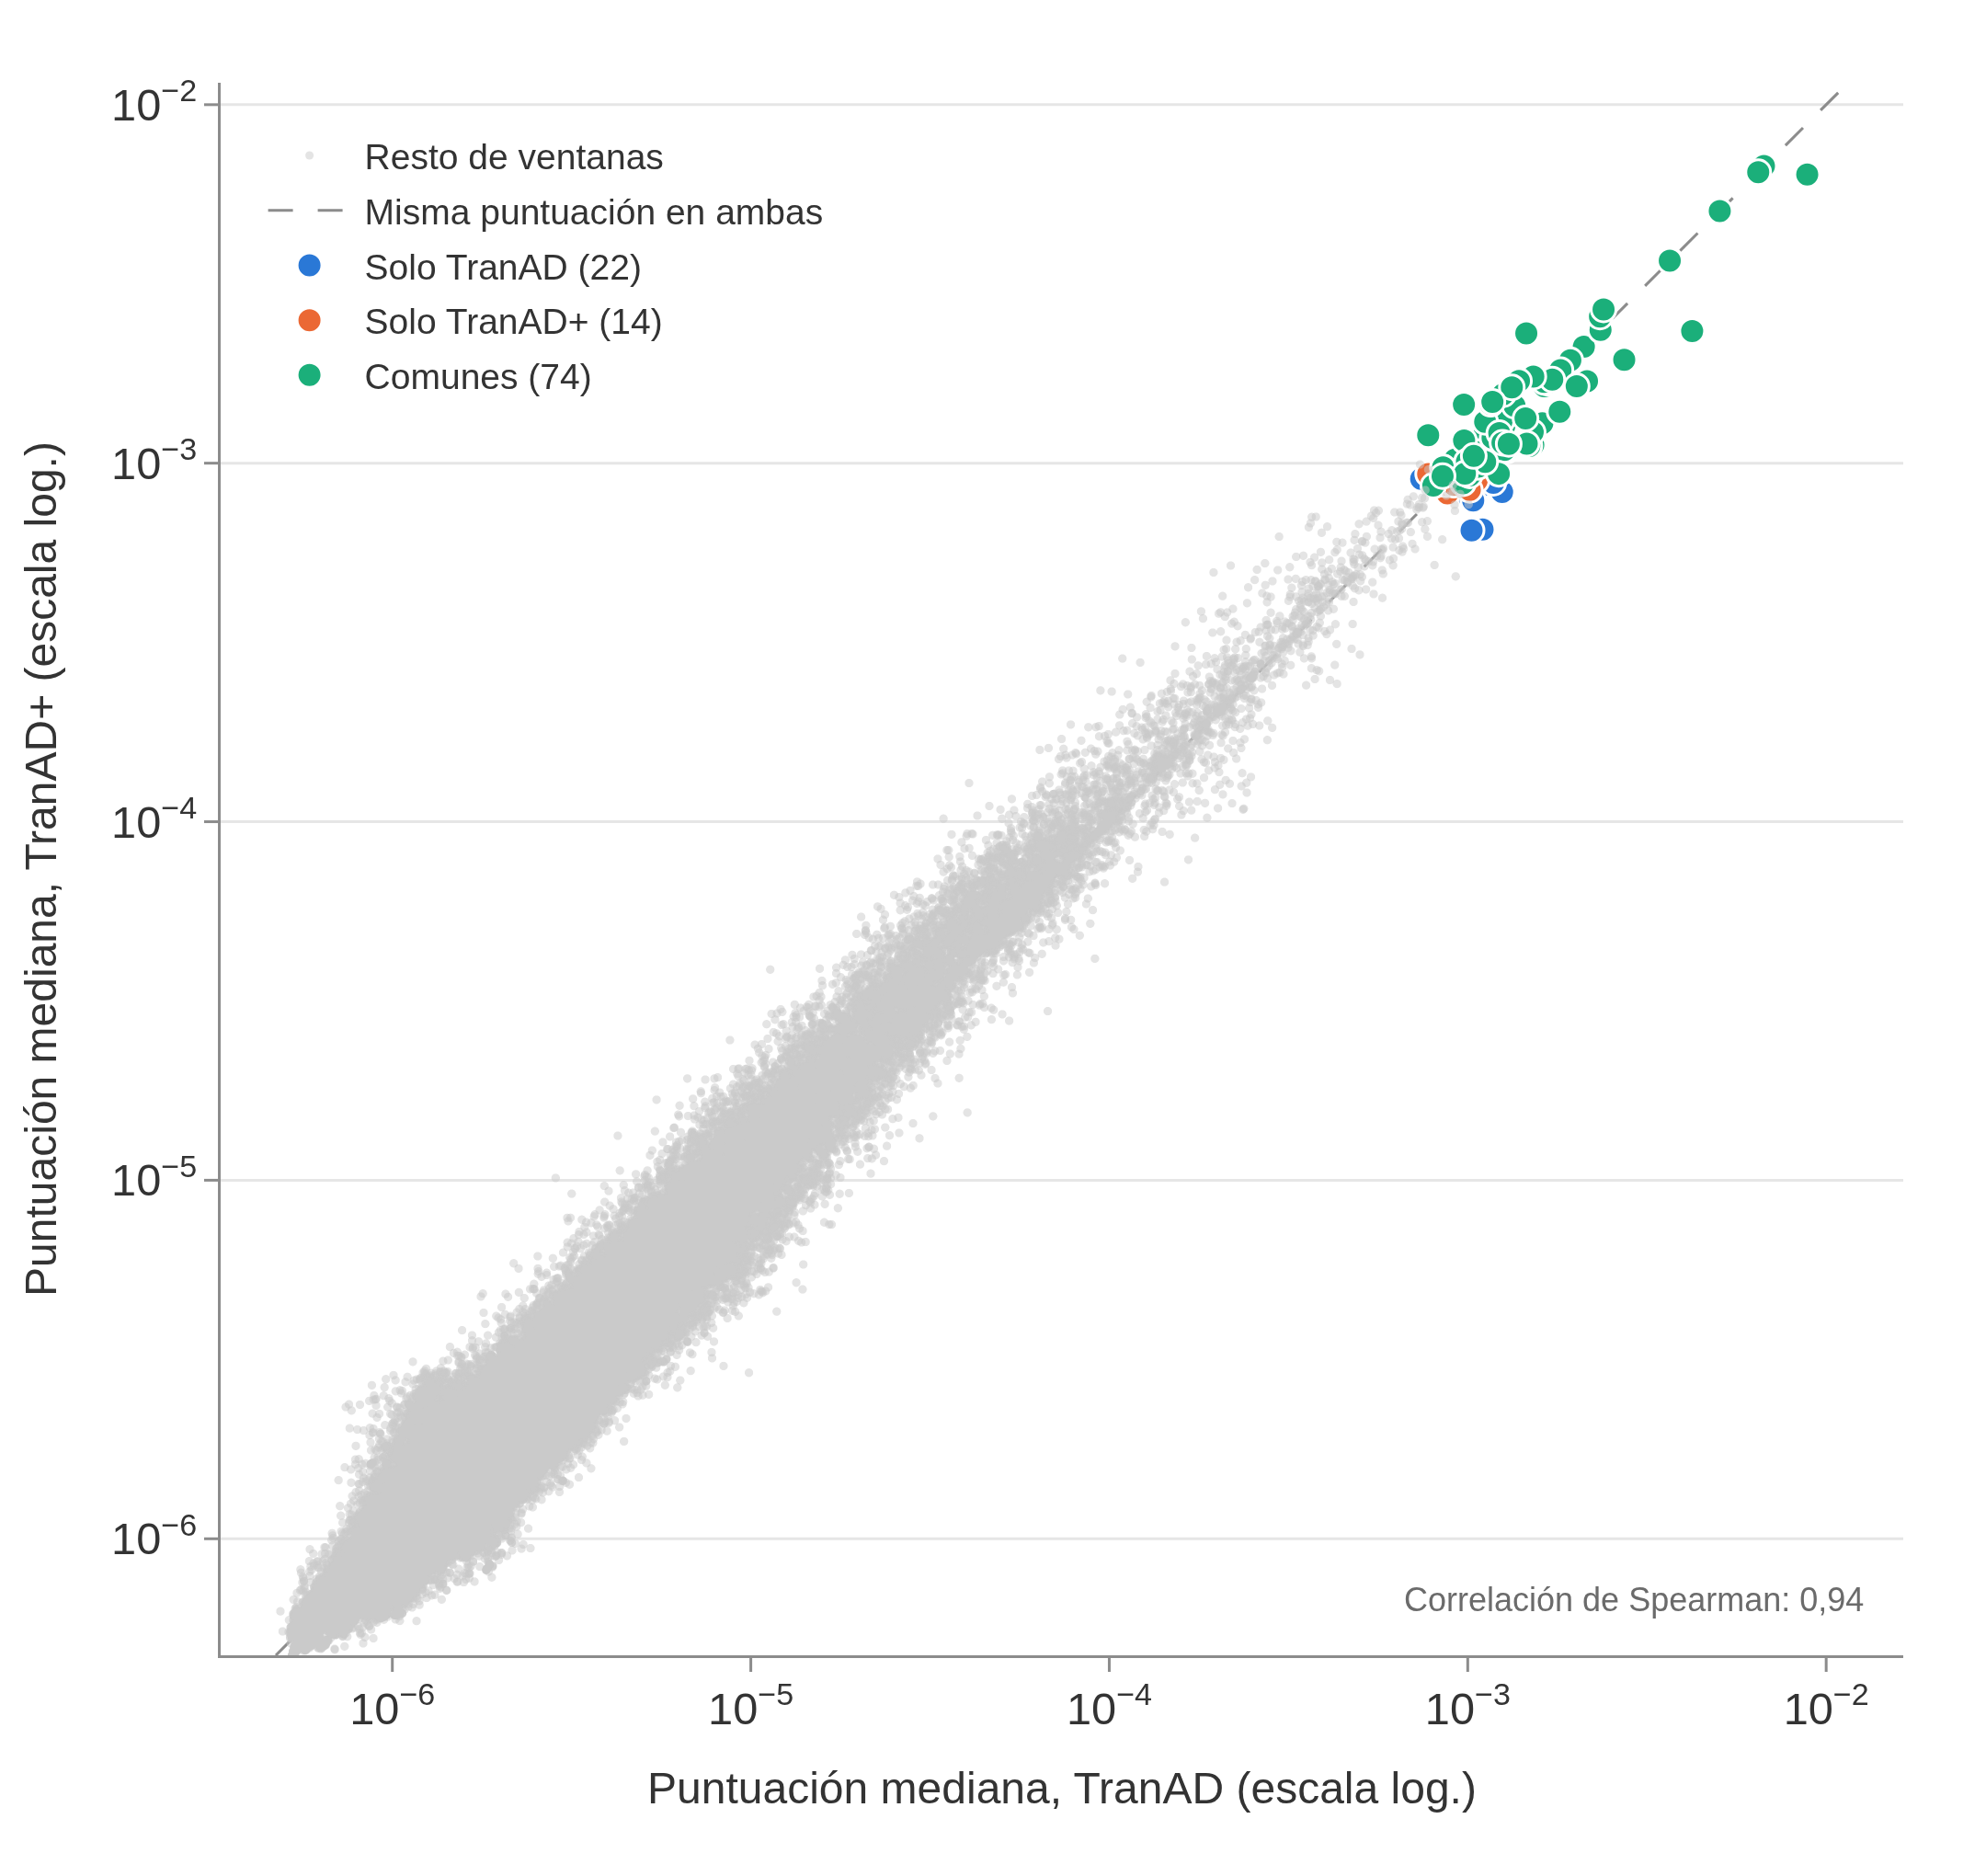

Figura guardada: fig_5_1_5_puntuacion_tranad_tranadplus (.html y .png)


In [12]:
# --- Puntuación mediana de cada ventana de prueba: TranAD frente a TranAD+ ---
mediana = {m: np.median(np.stack([puntuaciones[f"{m}_s{s}"] for s in SEMILLAS]), axis=0) for m in MODELOS}
x, y = mediana["tranad"], mediana["tranadplus"]
minimo = min(x[x > 0].min(), y[y > 0].min())  # la escala logarítmica necesita valores positivos
x, y = np.clip(x, minimo, None), np.clip(y, minimo, None)
correlacion = pd.Series(x).rank().corr(pd.Series(y).rank())  # Spearman = Pearson sobre los rangos
print(f"Correlación de Spearman entre las puntuaciones medianas: {correlacion:.3f}")
comprobar("correlación de Spearman entre arquitecturas", round(float(correlacion), 2), 0.94)
REGISTRO["resultados"]["spearman_puntuacion_mediana"] = round(float(correlacion), 3)

GRUPOS_D = [("solo_tranad", "Solo TranAD", COLOR_MODELO["tranad"]),
            ("solo_tranadplus", "Solo TranAD+", COLOR_MODELO["tranadplus"]),
            ("comun", "Comunes", COLOR_COMUN)]
resto = np.ones(N_TEST, dtype=bool)
for clave, _, _ in GRUPOS_D:
    resto[consenso[clave]] = False

fig = go.Figure()
fig.add_trace(go.Scattergl(x=x[resto], y=y[resto], mode="markers", name="Resto de ventanas",
                           marker=dict(size=3, color=GRIS, opacity=0.5), hoverinfo="skip"))
limites = [minimo, max(x.max(), y.max()) * 1.3]
fig.add_trace(go.Scatter(x=limites, y=limites, mode="lines", line=dict(color=GUIA, dash="dash", width=1),
                         name="Misma puntuación en ambas", hoverinfo="skip"))
for clave, nombre, color in GRUPOS_D:
    idx = consenso[clave]
    fig.add_trace(go.Scatter(
        x=x[idx], y=y[idx], mode="markers", name=f"{nombre} ({len(idx)})",
        marker=dict(size=9, color=color, line=dict(color="white", width=1)), customdata=idx,
        hovertemplate=(f"{nombre} · ventana %{{customdata}}<br>TranAD: %{{x:.3e}}<br>TranAD+: %{{y:.3e}}"
                       "<extra></extra>")))
rango_log = [np.log10(limites[0]), np.log10(limites[1])]
fig.update_xaxes(type="log", range=rango_log, dtick=1, exponentformat="power",
                 title_text="Puntuación mediana, TranAD (escala log.)")
fig.update_yaxes(type="log", range=rango_log, dtick=1, exponentformat="power",
                 title_text="Puntuación mediana, TranAD+ (escala log.)", scaleanchor="x", scaleratio=1)
fig.update_layout(legend=dict(orientation="v", x=0.02, y=0.98, xanchor="left", yanchor="top"), margin=dict(t=30))
fig.add_annotation(text=f"Correlación de Spearman: {correlacion:.2f}".replace(".", ","), xref="paper", yref="paper",
                   x=0.98, y=0.02, xanchor="right", yanchor="bottom", showarrow=False,
                   font=dict(size=12, color=TINTA_SUAVE))
guardar_figura(fig, "fig_5_1_5_puntuacion_tranad_tranadplus", ancho=720, alto=680)

## 8. Registro de resultados

Se guardan las cifras de cada sección, la lista de figuras y tablas (`registro_experimento_1.json`) y el resultado de las comprobaciones con la memoria (`comprobaciones_memoria.csv`).

In [13]:
# --- Guardado del registro y resumen de las comprobaciones ---
REGISTRO["fin"] = datetime.now().strftime("%Y-%m-%d %H:%M")
REGISTRO["comprobaciones"] = COMPROBACIONES
with open(f"{RUTA_EXPERIMENTO_1}/registro_experimento_1.json", "w", encoding="utf-8") as f:
    json.dump(REGISTRO, f, ensure_ascii=False, indent=1, default=a_python)

df_comprobaciones = pd.DataFrame(COMPROBACIONES)
df_comprobaciones.to_csv(f"{RUTA_EXPERIMENTO_1}/comprobaciones_memoria.csv", index=False)
distintas = df_comprobaciones[df_comprobaciones["resultado"] != "coincide"]
print(f"Figuras: {len(REGISTRO['figuras'])} ficheros | tablas: {len(REGISTRO['tablas'])}")
print(f"Comprobaciones: {len(df_comprobaciones)} | coinciden: {len(df_comprobaciones) - len(distintas)} | "
      f"distintas: {len(distintas)}")
display(distintas if len(distintas) else "Todas las cifras coinciden con la memoria")

Figuras: 12 ficheros | tablas: 4
Comprobaciones: 18 | coinciden: 18 | distintas: 0


'Todas las cifras coinciden con la memoria'